<a href="https://colab.research.google.com/github/Protmdd/BD_OECE_PROYECTO_DM/blob/main/Hito4_OECE_DiamondFinders_DM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HITO 4 | Proyecto OECE - Segmentación de proveedores (2021-2025)
**Curso:** Data Mining - Universidad del Pacífico  
**Equipo:** Diamond Finders  
**Técnica principal:** K-means sobre siete atributos transformados y estandarizados (sin PCA).  
**Producto de análisis:** perfiles de proveedores, composición provincial, figuras para el paper IEEE y mapa interactivo HTML.  

> **Regla de reproducibilidad:** los resultados y afirmaciones cuantitativas del paper y la exposición deben proceder de la ejecución de esta versión del notebook. La pauta exige además un paper IEEE y un repositorio reproducible, que se preparan fuera de este archivo.


## 00. Problema, usuario y pregunta de investigación

**Problema analítico.** Los registros de contratación pública permiten consultar procesos, postores y adjudicaciones, pero la información dispersa no identifica por sí sola **perfiles comparables de participación de los proveedores**, ni muestra claramente cómo varía su composición entre los mercados municipales provinciales. Esa ausencia de una síntesis descriptiva dificulta plantear preguntas focalizadas sobre concurrencia, recurrencia y alcance territorial.

**Pregunta:** *¿Qué perfiles de proveedores se distinguen por sus patrones de participación y adjudicación en las municipalidades provinciales del Perú durante 2021–2025, y cómo se distribuye su participación entre provincias?*

**Objetivo:** Obtener segmentos interpretables de proveedores mediante **K-means sin PCA**, caracterizarlos en unidades originales y representar su participación territorial con un mapa interactivo, explicitando limitaciones y posibles usos institucionales y empresariales.

**Usuario principal:**

- **OECE:** podría utilizar los resultados para complementar sus funciones de gestión de información, análisis del mercado de proveedores, supervisión selectiva y orientación a las entidades públicas. La segmentación permitiría identificar patrones de participación y adjudicación, así como diferencias territoriales que merezcan estudios posteriores.

**Usuarios secundarios:**

- **Municipalidades provinciales:** podrían conocer y comparar la composición de los proveedores que participan en sus procedimientos de contratación, identificando perfiles recurrentes, ocasionales y de mayor alcance territorial. Esta información serviría como apoyo descriptivo para analizar sus mercados de proveedores.

- **Empresas y potenciales proveedores del Estado:** podrían consultar los patrones históricos de participación y adjudicación de proveedores en distintas provincias, identificar qué perfiles predominan y comprender mejor las características de los mercados municipales. Esta información podría apoyar sus análisis preliminares para decidir dónde explorar oportunidades de contratación y cómo comprender el entorno competitivo, sin garantizar adjudicaciones ni estimar probabilidades de éxito.

**Unidades distintas:** cada fila del modelo = **RUC proveedor**; cada registro cartográfico = **par RUC–provincia donde participó**, que **no equivale a domicilio fiscal**.

**Advertencia de alcance:** la pertenencia a un cluster no demuestra ilegalidad, colusión, incumplimiento, falta de competencia ni elegibilidad; tampoco predice la adjudicación futura. Los resultados permiten caracterizar comportamientos históricos, pero no sustituir el análisis de requisitos, condiciones y oportunidades específicas de contratación. Los números publicados en el informe del Hito 3 son antecedentes sujetos a recálculo: las tablas definitivas deben salir de la ejecución actual de este notebook.

## 00.1. Pertinencia para los usuarios y alcance institucional

El objetivo es **convertir registros dispersos en una tipología descriptiva reproducible**, de modo que un usuario pueda interpretar cómo participan los proveedores y cómo cambia esa composición entre provincias. Esta motivación procede de la pregunta del proyecto por lo que la pertinencia académica se sustenta en sus datos y objetivos.

| Usuario | Pregunta que puede explorar | Aplicación prudente de los resultados |
|---|---|---|
| **OECE (principal)** | ¿Qué perfiles de participación y adjudicación existen y dónde predominan? | Gestión y evaluación de información, estudio descriptivo de mercados provinciales y formulación de preguntas para análisis posteriores de supervisión u orientación. |
| **Municipalidades provinciales** | ¿Qué perfiles de proveedores participan en sus procesos? | Comparar la composición de participantes con otras provincias, tomando en cuenta el volumen del mercado. |
| **Empresas y potenciales proveedores** | ¿Qué patrones históricos se observan en cada provincia? | Explorar la composición del mercado, sin inferir probabilidades de éxito ni recomendar dónde adjudicarse. |

**Vinculación con competencias del OECE.** La gestión de información y las actividades de supervisión y asistencia técnica permiten plantear estos usos **potenciales**, pero la segmentación no constituye una herramienta oficial, una alerta de fraude, una recomendación de adjudicación ni una evaluación del desempeño institucional. Para sustentar las funciones en el paper, consultar fuentes normativas primarias:

- [Ley N.º 32069, Ley General de Contrataciones Públicas, art. 11](https://cdn.www.gob.pe/uploads/document/file/7594705/6444155-ley-general-de-contrataciones-publicas-con-modificaciones-al-5-12-2025.pdf).
- [Reglamento de Organización y Funciones del OECE, arts. 4–5](https://cdn.www.gob.pe/uploads/document/file/7966127/6699379-anexo-resolucion-n-002-2025-oece-pre.pdf).

**Alcance de la evidencia:** base histórica de **2021–2025**, unidad **RUC**, datos espaciales como **provincia de participación** (no domicilio fiscal). Ninguna variable, índice o cluster demuestra causalidad, ilegalidad, barreras de acceso ni resultados de futuras convocatorias.


## Guía de cumplimiento de las pautas del Hito 4

**Lo que entrega este notebook:** carga y validación de fuentes; matriz de análisis; técnica y justificación; pipeline con ejemplo; configuraciones de K-means y métricas; resultados interpretables; análisis territorial; figura y **HTML**; exportación de evidencia y comprobaciones de reproducibilidad.

**Lo que debe completar el equipo fuera del notebook (exigencia de la pauta):**

1. **Paper completo en LaTeX, estilo IEEE.** Resumen de **150–250 palabras**, **3–5 palabras clave**, y secciones I–VII: Introducción, Datos y representación, Metodología, Diseño experimental, Resultados, Discusión, Conclusiones. Referencias citadas con formato IEEE.
2. **Sección III del paper:** insertar la figura `pipeline.png` e ilustrar con un caso el paso desde una fila de proveedor hasta el segmento y su participación provincial.
3. **Sección V del paper:** utilizar las tablas y figuras exportadas; incluir captura del mapa, pie de figura, fuente, denominadores e interpretación (no solo métricas).
4. **Secciones VI y VII:** responder la pregunta, describir utilidad y limitaciones, formular conclusiones respaldadas y recomendaciones condicionadas.
5. **GitHub:** incorporar notebook, `requirements.txt`, `README.md`, instrucciones de acceso a datos, tablas/figuras, HTML y enlace al repositorio en el PDF y en Blackboard. Comprobar ejecución desde cero.
6. **Exposición:** 12 min + 5 min de preguntas; priorizar hallazgos, interpretación, limitaciones y conclusiones; evitar mostrar código o repetir la limpieza detallada.

> Esta guía sigue las **pautas de entrega** adjuntas; no sustituye la revisión final del paper, la presentación o el repositorio. Las métricas deben recalcularse en el dataset real.


# <font color=green>01. Entorno, fuentes y carga reproducible</font>
En esta sección centralizamos la semilla aleatoria (`SEED = 1`), las rutas de exportación (`outputs/tablas`, `outputs/figuras`, `outputs/mapas`) y las funciones modulares de carga y auditoría (`cargar_datos()`, `cargar_limites()`, `validar_cobertura()`). Cualquier inconsistencia en llaves, tipos de datos, fechas o rangos detiene la ejecución de forma explícita.

In [ ]:
import json
import os
import subprocess
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd
import plotly.graph_objects as go
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
sns.set_theme(style="ticks")

SEED = 1
MIN_PROVEEDORES = 100

RUTA_OUTPUTS = Path("outputs")
RUTA_TABLAS = RUTA_OUTPUTS / "tablas"
RUTA_FIGURAS = RUTA_OUTPUTS / "figuras"
RUTA_MAPAS = RUTA_OUTPUTS / "mapas"

for carpeta in [RUTA_TABLAS, RUTA_FIGURAS, RUTA_MAPAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

REPO_DATOS = "https://github.com/Protmdd/Matriz_Integrada_DM_OECE.git"
REPO_LIMITES = "https://github.com/josedaniel-cb/limites-peru-geojson.git"
ARCHIVO_EXCEL = Path(os.getenv("OECE_EXCEL", "Matriz_Integrada_DM_OECE/proveedores_integrado.xlsx"))
ARCHIVO_LIM_JSON = Path(os.getenv("OECE_GEOJSON", "limites-peru-geojson/LIM_PROVINCIAL_PERU.json"))
ARCHIVO_GEOJSON_ALT = Path("limites-peru-geojson/peru_provincial_simple.geojson")

# Esta lista define el modelo; NO depende de las variables mostradas en la matriz de correlaciones.
VARIABLES = [
    "n_convocatorias",
    "n_items_adjudicados",
    "tasa_adjudicacion",
    "monto_total_adjudicado",
    "n_municipalidades",
    "n_rubros",
    "dias_trayectoria",
]
# Vista resumida opcional para presentación: se oculta el conteo de ítems solo en el gráfico.
VARIABLES_CORR_VISUAL = [col for col in VARIABLES if col != "n_items_adjudicados"]
assert len(VARIABLES_CORR_VISUAL) == len(VARIABLES) - 1


In [ ]:
# @title
def normalizar_texto(texto):
    """Convierte a mayúsculas, elimina espacios extremos y suprime tildes."""
    texto = unicodedata.normalize("NFKD", str(texto).upper().strip())
    return "".join(c for c in texto if not unicodedata.combining(c))


def clonar_repositorios():
    for url, carpeta in [(REPO_DATOS, "Matriz_Integrada_DM_OECE"), (REPO_LIMITES, "limites-peru-geojson")]:
        if not os.path.exists(carpeta):
            subprocess.run(["git", "clone", "--depth", "1", url, carpeta], check=True)


def cargar_datos(ruta_excel=ARCHIVO_EXCEL):
    if not ruta_excel.exists():
        if str(ruta_excel).startswith("Matriz_Integrada_DM_OECE"):
            subprocess.run(["git", "clone", "--depth", "1", REPO_DATOS, "Matriz_Integrada_DM_OECE"], check=True)
        else:
            raise FileNotFoundError(f"No existe el Excel local indicado en OECE_EXCEL: {ruta_excel}")
    assert ruta_excel.exists(), f"No se encontró el archivo de datos: {ruta_excel}"
    df = pd.read_excel(ruta_excel, sheet_name="dataset_integrado")

    cols_requeridas = {
        "ruc_proveedor", "n_convocatorias", "n_items_adjudicados",
        "tasa_adjudicacion", "monto_total_adjudicado", "n_rubros",
        "primera_participacion", "ultima_participacion",
        "municipalidades_participacion", "provincias_participacion",
    }
    faltantes = cols_requeridas - set(df.columns)
    assert not faltantes, f"Faltan columnas obligatorias en el Excel: {faltantes}"

    df["ruc_proveedor"] = df["ruc_proveedor"].astype(str).str.strip()
    df["primera_participacion"] = pd.to_datetime(df["primera_participacion"], errors="raise")
    df["ultima_participacion"] = pd.to_datetime(df["ultima_participacion"], errors="raise")

    # Semántica: conteo de municipalidades provinciales distintas separadas por coma en el registro agregado
    df["n_municipalidades"] = df["municipalidades_participacion"].fillna("").apply(
        lambda t: len({m.strip() for m in str(t).split(",") if m.strip()})
    )
    df["dias_trayectoria"] = (df["ultima_participacion"] - df["primera_participacion"]).dt.days
    return df


def validar_cobertura(df):
    assert df["ruc_proveedor"].notna().all(), "Existen RUC nulos."
    assert df["ruc_proveedor"].is_unique, "Existen RUC duplicados en la matriz."
    assert len(df) > 0, "El DataFrame está vacío."
    assert df["tasa_adjudicacion"].between(0, 1).all(), "tasa_adjudicacion fuera del rango [0, 1]."
    assert (df["n_convocatorias"] >= 1).all(), "Existen proveedores con n_convocatorias < 1."
    assert (df["n_items_adjudicados"] >= 0).all(), "n_items_adjudicados negativo."
    assert (df["monto_total_adjudicado"] >= 0).all(), "monto_total_adjudicado negativo."
    assert (df["n_municipalidades"] >= 1).all(), "n_municipalidades < 1."
    assert (df["n_rubros"] >= 1).all(), "n_rubros < 1."
    assert (df["dias_trayectoria"] >= 0).all(), "dias_trayectoria negativo."
    assert df[VARIABLES].isna().sum().sum() == 0, "Existen valores nulos en las 7 variables del modelo."

    provincias_datos = {
        normalizar_texto(p)
        for t in df["provincias_participacion"].fillna("")
        for p in str(t).split(",")
        if p.strip()
    }
    resumen = pd.DataFrame([{
        "n_proveedores": len(df),
        "n_columnas": df.shape[1],
        "ruc_unicos": df["ruc_proveedor"].nunique(),
        "nulos_7_variables": int(df[VARIABLES].isna().sum().sum()),
        "fecha_min": str(df["primera_participacion"].min().date()),
        "fecha_max": str(df["ultima_participacion"].max().date()),
        "provincias_distintas_datos": len(provincias_datos),
    }])
    resumen.to_csv(RUTA_TABLAS / "validacion_entrada.csv", index=False)
    return resumen


df = cargar_datos()
resumen_validacion = validar_cobertura(df)
display(resumen_validacion)
display(df[["ruc_proveedor"] + VARIABLES].head())

,n_proveedores,n_columnas,ruc_unicos,nulos_7_variables,fecha_min,fecha_max,provincias_distintas_datos
0,47281,18,47281,0,2021-01-04,2025-12-31,196


,ruc_proveedor,n_convocatorias,n_items_adjudicados,tasa_adjudicacion,monto_total_adjudicado,n_municipalidades,n_rubros,dias_trayectoria
0,10000196610,1,0,0.000,0.00,1,1,0
1,10000235071,3,1,0.333,96000.00,1,1,367
2,10000636369,2,1,0.500,55000.00,2,1,335
3,10000697945,12,3,0.214,506533.06,1,1,1096
4,10000701292,1,0,0.000,0.00,1,1,0


## 02. Matriz analítica, correlación y representación (siete atributos)

**Modelo:** se emplean las siete variables numéricas de participación, adjudicación y escala, municipio, rubro y trayectoria listadas en `VARIABLES`, después de `log1p` selectivo y Z-score, **sin PCA**.

**Solicitud de presentación:** en la figura introductoria **no mostramos** `n_items_adjudicados`, porque las correlaciones con tasa y monto de adjudicación pueden ser en parte esperables por su construcción o por el predominio de ceros. **Esto NO equivale a retirarla del modelo**: el diagnóstico completo de las siete variables se calcula y guarda en CSV, y más adelante se prueba expresamente si omitir ese atributo cambia los resultados de K-means. Ocultar una columna solo por estética no resolvería redundancia estadística.

**Importante sobre causalidad y método:** la correlación de Pearson no demuestra causalidad ni justifica por sí sola la supresión de atributos; K-means usa distancias y la presencia de variables que representan dimensiones relacionadas puede aumentar el peso de dichas dimensiones. La comparación de sensibilidad evalúa ese efecto en la práctica.

**Definición de tasa:** el cociente exacto debe verificarse contra el proceso de integración del Hito 2 (unidad: ítem frente a convocatoria); la matriz cargada contiene una tasa ya elaborada. No se deduce su fórmula únicamente a partir de su rango 0–1.

**Peligro:** la correlación alta entre adjudicación y monto, especialmente con muchos proveedores con cero adjudicaciones, es un **diagnóstico metodológico**, no un hallazgo sustantivo nuevo sobre el mercado. Valores extremos y perfiles repetidos pueden afectar las métricas internas.


In [ ]:
# @title
asimetria_antes = df[VARIABLES].skew()
cols_log = [c for c in VARIABLES if asimetria_antes[c] > 1]

X_log = df[VARIABLES].copy()
X_log[cols_log] = np.log1p(X_log[cols_log])

scaler = StandardScaler()
X_z = scaler.fit_transform(X_log)
df_z = pd.DataFrame(X_z, columns=VARIABLES, index=df.index)

tabla_eda = pd.DataFrame({
    "Min": df[VARIABLES].min(),
    "Mediana": df[VARIABLES].median(),
    "Media": df[VARIABLES].mean(),
    "Max": df[VARIABLES].max(),
    "Asimetria_Antes": asimetria_antes,
    "Asimetria_Despues_log1p": X_log.skew(),
    "Transformada_log1p": [c in cols_log for c in VARIABLES],
    "IQR_log1p": X_log.quantile(0.75) - X_log.quantile(0.25),
})
display(tabla_eda.round(2))

pct_perfiles_duplicados = df_z.round(6).duplicated().mean() * 100
n_perfiles_unicos = int((~df_z.round(6).duplicated()).sum())
print(f"RUC duplicados: {df['ruc_proveedor'].duplicated().sum()} (unicidad garantizada)")
print(f"Proveedores con vector de 7 atributos exactamente repetido: {pct_perfiles_duplicados:.1f}% ({n_perfiles_unicos} perfiles únicos de {len(df)})")

,Min,Mediana,Media,Max,Asimetria_Antes,Asimetria_Despues_log1p,Transformada_log1p,IQR_log1p
n_convocatorias,1.0,1.0,2.68,1.229e+03,49.83,2.90,True,0.41
n_items_adjudicados,0.0,0.0,0.78,6.130e+02,102.96,1.80,True,0.69
tasa_adjudicacion,0.0,0.0,0.35,1.000e+00,0.63,0.63,False,1.00
monto_total_adjudicado,0.0,0.0,535778.77,2.285e+08,28.20,0.35,True,12.12
n_municipalidades,1.0,1.0,1.57,1.050e+02,13.85,3.82,True,0.00
n_rubros,1.0,1.0,1.04,3.000e+00,5.30,5.05,True,0.00
dias_trayectoria,0.0,0.0,149.76,1.817e+03,2.68,1.44,True,0.00


RUC duplicados: 0 (unicidad garantizada)
Proveedores con vector de 7 atributos exactamente repetido: 53.9% (21810 perfiles únicos de 47281)


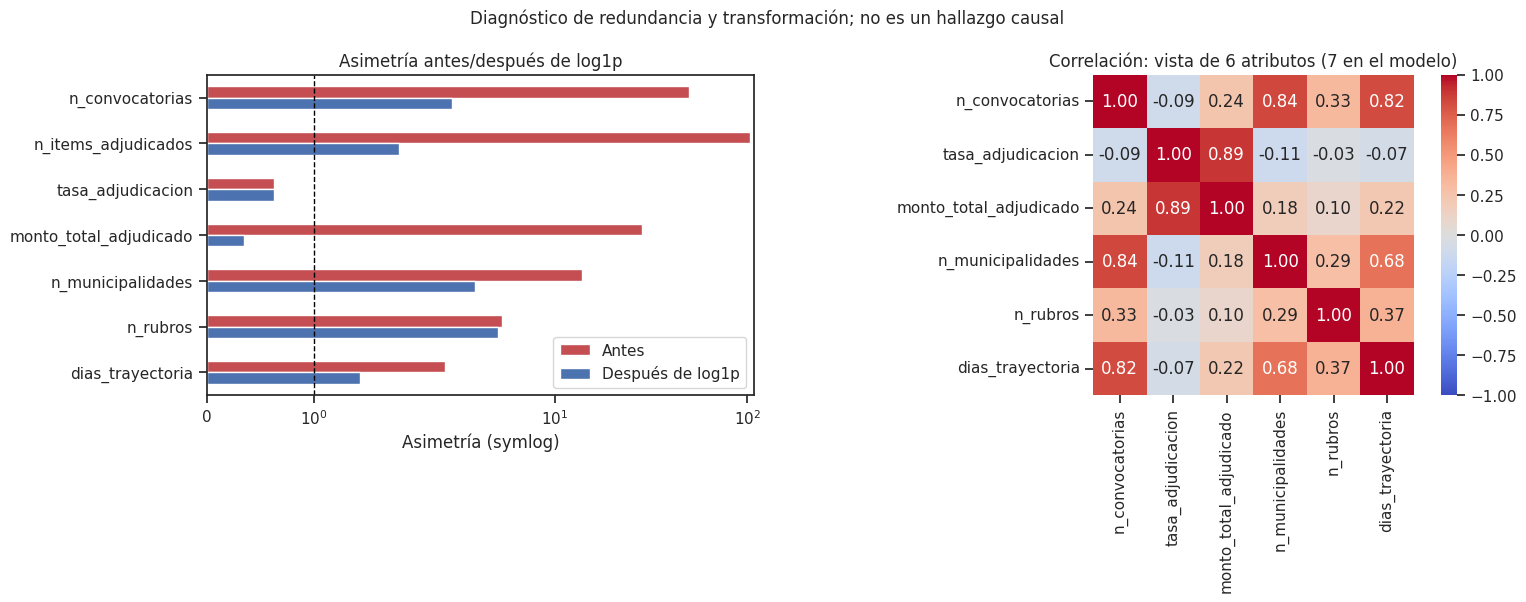

Atributo omitido SOLO de la figura: n_items_adjudicados
Variables del modelo: ['n_convocatorias', 'n_items_adjudicados', 'tasa_adjudicacion', 'monto_total_adjudicado', 'n_municipalidades', 'n_rubros', 'dias_trayectoria']
Diagnóstico sin log1p (k=4), tamaños mínimos/máximos: 1 27980
Diagnóstico sin log1p (k=5), tamaños mínimos/máximos: 1 26693
Diagnóstico sin log1p (k=6), tamaños mínimos/máximos: 1 26695


In [ ]:
# @title
# Diagnóstico gráfico: se presenta una vista resumida de correlaciones (6 atributos).
# El modelo X_z sigue utilizando las 7 variables, incluida n_items_adjudicados.
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.0))

tabla_eda[["Asimetria_Antes", "Asimetria_Despues_log1p"]].rename(
    columns={"Asimetria_Antes": "Antes", "Asimetria_Despues_log1p": "Después de log1p"}
).plot.barh(ax=axes[0], color=["#c44e52", "#4c72b0"])
axes[0].axvline(1, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Asimetría antes/después de log1p", xlabel="Asimetría (symlog)", xscale="symlog")
axes[0].invert_yaxis()

correlaciones_completas = df_z[VARIABLES].corr()
correlaciones_completas.to_csv(RUTA_TABLAS / "correlaciones_7_atributos_completa.csv")
correlaciones_visuales = correlaciones_completas.loc[VARIABLES_CORR_VISUAL, VARIABLES_CORR_VISUAL]
sns.heatmap(correlaciones_visuales, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title("Correlación: vista de 6 atributos (7 en el modelo)")
plt.suptitle("Diagnóstico de redundancia y transformación; no es un hallazgo causal", fontsize=12)
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "diagnostico_correlaciones_6_mostradas.png", dpi=250, bbox_inches="tight")
plt.show()
print("Atributo omitido SOLO de la figura: n_items_adjudicados")
print("Variables del modelo:", VARIABLES)

# Diagnóstico de referencia: K-means sin log1p sobre los 7 atributos (no es la solución final).
X_sin_log = StandardScaler().fit_transform(df[VARIABLES])
for k_diag in [4, 5, 6]:
    lab_diag = KMeans(n_clusters=k_diag, n_init=10, random_state=SEED).fit_predict(X_sin_log)
    print(f"Diagnóstico sin log1p (k={k_diag}), tamaños mínimos/máximos:",
          int(np.bincount(lab_diag).min()), int(np.bincount(lab_diag).max()))

**Lectura metodológica.** `log1p` reduce la influencia de magnitudes extremas, pero no garantiza grupos equilibrados ni elimina todos los efectos de asimetría. El pequeño diagnóstico anterior compara tamaños con y sin transformación sobre los datos actualmente cargados. La matriz de correlaciones presentada tiene seis atributos **solo por legibilidad**; todos los análisis de K-means de la sección 04 siguen usando los siete atributos indicados en `VARIABLES`. **No se deducen nuevos hallazgos económicos de correlaciones mecánicas.**

# <font color=green>03. Pipeline metodológico con ejemplo trazable</font>
Generamos el diagrama del pipeline metodológico (exportado en `outputs/figuras/pipeline.png` para la Sección III del paper IEEE) y documentamos cómo se transforma una observación real a lo largo de todas las etapas.

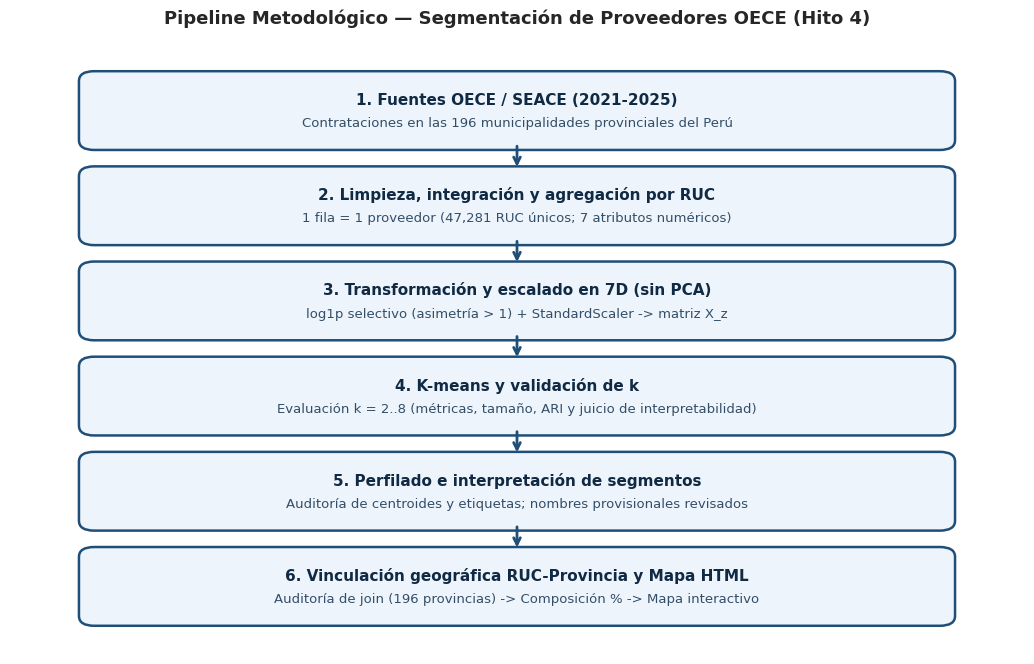

In [ ]:
def graficar_pipeline(ruta_salida=RUTA_FIGURAS / "pipeline.png"):
    pasos = [
        ("1. Fuentes OECE / SEACE (2021-2025)", "Contrataciones en las 196 municipalidades provinciales del Perú"),
        ("2. Limpieza, integración y agregación por RUC", f"1 fila = 1 proveedor ({len(df):,} RUC únicos; 7 atributos numéricos)"),
        ("3. Transformación y escalado en 7D (sin PCA)", "log1p selectivo (asimetría > 1) + StandardScaler -> matriz X_z"),
        ("4. K-means y validación de k", "Evaluación k = 2..8 (métricas, tamaño, ARI y juicio de interpretabilidad)"),
        ("5. Perfilado e interpretación de segmentos", "Auditoría de centroides y etiquetas; nombres provisionales revisados"),
        ("6. Vinculación geográfica RUC-Provincia y Mapa HTML", "Auditoría de join (196 provincias) -> Composición % -> Mapa interactivo"),
    ]
    fig, ax = plt.subplots(figsize=(10.5, 6.8))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, len(pasos) * 1.48 + 0.5)
    ax.axis("off")

    for idx, (titulo, detalle) in enumerate(pasos):
        y = (len(pasos) - 1 - idx) * 1.45 + 0.55
        caja = mpatches.FancyBboxPatch(
            (0.8, y), 8.4, 0.96,
            boxstyle="round,pad=0.12,rounding_size=0.15",
            ec="#1f4e78", fc="#edf4fc", lw=1.8
        )
        ax.add_patch(caja)
        ax.text(5.0, y + 0.64, titulo, ha="center", va="center", fontsize=11, fontweight="bold", color="#102a43")
        ax.text(5.0, y + 0.28, detalle, ha="center", va="center", fontsize=9.5, color="#334e68")
        if idx < len(pasos) - 1:
            ax.annotate(
                "", xy=(5.0, y - 0.42), xytext=(5.0, y - 0.02),
                arrowprops=dict(arrowstyle="->", lw=2.0, color="#1f4e78")
            )

    ax.set_title("Pipeline Metodológico — Segmentación de Proveedores OECE (Hito 4)", fontsize=13, fontweight="bold", pad=10)
    plt.tight_layout()
    fig.savefig(ruta_salida, dpi=300, bbox_inches="tight")
    plt.show()


graficar_pipeline()

In [ ]:
# Ejemplo trazable de un proveedor real de la matriz (anonimizado como RUC_ILUSTRATIVO)
idx_ejemplo = 2
tabla_ejemplo_pipeline = pd.DataFrame({
    "Atributo": VARIABLES,
    "1_Valor_Original": df.loc[idx_ejemplo, VARIABLES].values,
    "2_Tras_log1p": X_log.loc[idx_ejemplo, VARIABLES].round(3).values,
    "3_Estandarizado_Xz": df_z.loc[idx_ejemplo, VARIABLES].round(3).values,
})
print(f"Trazabilidad de proveedor ilustrativo (índice={idx_ejemplo}, RUC anonimizado: RUC_EJEMPLO_{idx_ejemplo}):")
print("Provincias de participación registradas:", df.loc[idx_ejemplo, "provincias_participacion"])
display(tabla_ejemplo_pipeline)

Trazabilidad de proveedor ilustrativo (índice=2, RUC anonimizado: RUC_EJEMPLO_2):
Provincias de participación registradas: BELLAVISTA, DATEM DEL MARAÑON


,Atributo,1_Valor_Original,2_Tras_log1p,3_Estandarizado_Xz
0,n_convocatorias,2,1.099,0.241
1,n_items_adjudicados,1,0.693,0.626
2,tasa_adjudicacion,0.5,0.500,0.322
3,monto_total_adjudicado,55000.0,10.915,0.860
4,n_municipalidades,2,1.099,0.746
5,n_rubros,1,0.693,-0.197
6,dias_trayectoria,335,5.817,1.723


# <font color=green>04. K-means: diseño experimental y selección de $k$ en $X_z$</font>
Evaluamos $k \in \{2, 3, 4, 5, 6, 7, 8\}$ sobre la única matriz candidata `X_z` (7 atributos estandarizados), con `n_init = 10` y `random_state = SEED`.  
**Criterios de decisión predefinidos:**
1. Tamaño del cluster más pequeño $\ge 1.0\%$ del padrón (dependiendo del tamaño actual de la matriz).
2. Estabilidad entre semillas aleatorias $\text{ARI}_{\text{semillas}} \ge 0.90$.
3. Coeficiente de Silueta (evaluado sobre la misma muestra aleatoria fija de hasta $5\,000$ proveedores), índice de Davies-Bouldin (menor es mejor) y Calinski-Harabasz (mayor es mejor).
4. Utilidad analítica y diferenciación sustantiva de los perfiles resultantes.

In [ ]:
# @title
TAM_MUESTRA_SILUETA = 5000  # fijo para todas las configuraciones; reduce costo cuadrático en Colab
muestra_z = np.random.RandomState(SEED).choice(len(X_z), size=min(TAM_MUESTRA_SILUETA, len(X_z)), replace=False)
semillas_contraste = [2, 3, 4, 5, 6]
rango_k = range(2, 9)

filas_k = []
modelos_kmeans = {}

for k in rango_k:
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_z)
    lab = modelo_k.labels_
    modelos_kmeans[k] = modelo_k

    tamanos = np.bincount(lab)
    aris_sem = [
        adjusted_rand_score(lab, KMeans(n_clusters=k, n_init=10, random_state=s).fit(X_z).labels_)
        for s in semillas_contraste
    ]

    filas_k.append({
        "k": k,
        "Inercia": float(modelo_k.inertia_),
        "Inercia_relativa_k2": float(modelo_k.inertia_),
        "Silueta": float(silhouette_score(X_z[muestra_z], lab[muestra_z])),
        "Davies_Bouldin": float(davies_bouldin_score(X_z, lab)),
        "Calinski_Harabasz": float(calinski_harabasz_score(X_z, lab)),
        "Tam_min": int(tamanos.min()),
        "Tam_min_pct": float(100.0 * tamanos.min() / len(X_z)),
        "Tam_max_pct": float(100.0 * tamanos.max() / len(X_z)),
        "ARI_semillas_media": float(np.mean(aris_sem)),
        "ARI_semillas_min": float(np.min(aris_sem)),
    })

comparacion_k = pd.DataFrame(filas_k)
comparacion_k["Inercia_relativa_k2"] = comparacion_k["Inercia"] / comparacion_k["Inercia"].iloc[0]
comparacion_k.to_csv(RUTA_TABLAS / "comparacion_kmeans_k.csv", index=False)
display(comparacion_k.round(3))

,k,Inercia,Inercia_relativa_k2,Silueta,Davies_Bouldin,Calinski_Harabasz,Tam_min,Tam_min_pct,Tam_max_pct,ARI_semillas_media,ARI_semillas_min
0,2,206636.637,1.000,0.615,0.930,28447.120,20398,43.142,56.858,1.0,1.000
1,3,119439.006,0.578,0.729,0.877,41865.006,6327,13.382,53.762,1.0,1.000
2,4,83364.365,0.403,0.761,0.844,46806.246,1809,3.826,53.123,1.0,0.999
3,5,62550.949,0.303,0.783,0.856,50717.230,1594,3.371,49.371,1.0,1.000
4,6,45764.264,0.221,0.813,0.761,58923.563,1276,2.699,48.036,1.0,1.000
5,7,40650.748,0.197,0.812,0.844,56269.622,537,1.136,48.007,1.0,1.000
6,8,36318.868,0.176,0.810,0.912,54788.161,513,1.085,48.007,1.0,1.000


In [ ]:
# @title
# Resumen reproducible para justificar el número de grupos sin repetir cifras antiguas.
columnas_decision = ["k", "Silueta", "Davies_Bouldin", "Calinski_Harabasz", "Tam_min_pct", "ARI_semillas_min"]
resumen_decision = comparacion_k[columnas_decision].copy()
resumen_decision["Supera_1pct"] = resumen_decision["Tam_min_pct"].ge(1.0)
resumen_decision["Supera_ARI_090"] = resumen_decision["ARI_semillas_min"].ge(0.90)
resumen_decision.to_csv(RUTA_TABLAS / "criterios_decision_k.csv", index=False)
print("Comparación observada: k=5, k=6 y k=7 (resultados de la matriz cargada)")
display(resumen_decision.set_index("k").loc[[5, 6, 7]].round(3))
print("Máxima silueta:", int(comparacion_k.loc[comparacion_k['Silueta'].idxmax(), 'k']))
print("Mínimo Davies-Bouldin:", int(comparacion_k.loc[comparacion_k['Davies_Bouldin'].idxmin(), 'k']))
print("Máximo Calinski-Harabasz:", int(comparacion_k.loc[comparacion_k['Calinski_Harabasz'].idxmax(), 'k']))
print("La decisión final de k requiere también revisar la interpretación sustantiva de los perfiles.")
if not bool(resumen_decision.set_index("k").loc[6, ["Supera_1pct", "Supera_ARI_090"]].all()):
    print("ADVERTENCIA: k=6 no cumple todos los filtros de tamaño/ARI en esta ejecución. Revisar la elección antes de publicar.")

Comparación observada: k=5, k=6 y k=7 (resultados de la matriz cargada)


,Silueta,Davies_Bouldin,Calinski_Harabasz,Tam_min_pct,ARI_semillas_min,Supera_1pct,Supera_ARI_090
k,,,,,,,
5,0.783,0.856,50717.230,3.371,1.0,True,True
6,0.813,0.761,58923.563,2.699,1.0,True,True
7,0.812,0.844,56269.622,1.136,1.0,True,True


Máxima silueta: 6
Mínimo Davies-Bouldin: 6
Máximo Calinski-Harabasz: 6
La decisión final de k requiere también revisar la interpretación sustantiva de los perfiles.


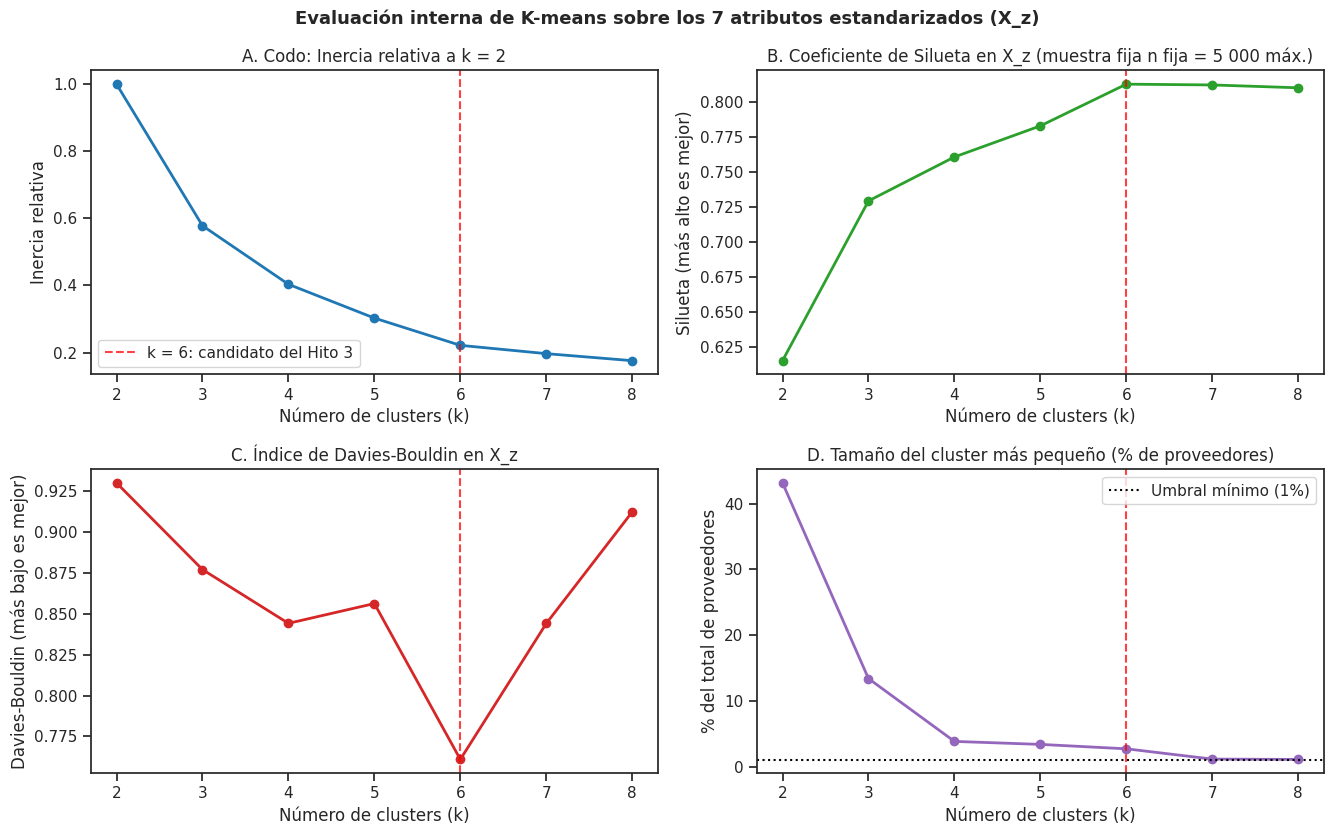

In [ ]:
# @title
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))

axes[0, 0].plot(comparacion_k["k"], comparacion_k["Inercia_relativa_k2"], marker="o", lw=2, color="#1f77b4")
axes[0, 0].axvline(6, color="red", linestyle="--", alpha=0.75, label="k = 6: candidato del Hito 3")
axes[0, 0].set(title="A. Codo: Inercia relativa a k = 2", xlabel="Número de clusters (k)", ylabel="Inercia relativa")
axes[0, 0].legend()

axes[0, 1].plot(comparacion_k["k"], comparacion_k["Silueta"], marker="o", lw=2, color="#2ca02c")
axes[0, 1].axvline(6, color="red", linestyle="--", alpha=0.75)
axes[0, 1].set(title="B. Coeficiente de Silueta en X_z (muestra fija n fija = 5 000 máx.)", xlabel="Número de clusters (k)", ylabel="Silueta (más alto es mejor)")

axes[1, 0].plot(comparacion_k["k"], comparacion_k["Davies_Bouldin"], marker="o", lw=2, color="#d62728")
axes[1, 0].axvline(6, color="red", linestyle="--", alpha=0.75)
axes[1, 0].set(title="C. Índice de Davies-Bouldin en X_z", xlabel="Número de clusters (k)", ylabel="Davies-Bouldin (más bajo es mejor)")

axes[1, 1].plot(comparacion_k["k"], comparacion_k["Tam_min_pct"], marker="o", lw=2, color="#9467bd")
axes[1, 1].axhline(1.0, color="black", linestyle=":", label="Umbral mínimo (1%)")
axes[1, 1].axvline(6, color="red", linestyle="--", alpha=0.75)
axes[1, 1].set(title="D. Tamaño del cluster más pequeño (% de proveedores)", xlabel="Número de clusters (k)", ylabel="% del total de proveedores")
axes[1, 1].legend()

plt.suptitle("Evaluación interna de K-means sobre los 7 atributos estandarizados (X_z)", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "seleccion_k.png", dpi=300, bbox_inches="tight")
plt.show()

**Selección de k (candidata, no verdad de antemano).** La configuración de referencia es `k=6` por los resultados del Hito 3 **sin PCA**, pero la evidencia válida para esta entrega es la calculada en `comparacion_k`. Revisar la silueta, Davies-Bouldin, Calinski-Harabasz, el tamaño del cluster menor (objetivo mínimo 1 %), la estabilidad (ARI) y la **interpretabilidad**. Ninguna métrica certifica por sí sola la existencia de grupos naturales. Si los valores cambian, documentar el motivo antes de usar la misma decisión. No comparar directamente índices internos entre representaciones distintas.

# <font color=green>05. Validación, sensibilidad de segmentos y renumeración determinista</font>
Evaluamos la solución **candidata** $k_{final} = 6$ sobre `X_z` y debemos confirmar su defendibilidad con las tablas calculadas; aplicamos una renumeración determinista de los clusters (`cluster_original` $\rightarrow$ `cluster_final`) y ejecutamos cuatro pruebas de robustez:
1. **Estabilidad frente a semillas (`ARI_semillas`):** verifica que la partición no dependa de los centroides iniciales.
2. **Sensibilidad al muestreo (`ARI_submuestra`):** entrena K-means en una submuestra de $22\,000$ proveedores y predice sobre los $47\,281$ con `.predict(X_z)`.
3. **Silueta por segmento y proporción de siluetas negativas:** cuantifica qué segmentos tienen fronteras nítidas y cuáles presentan transición gradual.
4. **Sensibilidad a perfiles repetidos:** evalúa qué ocurre con la silueta cuando se colapsan las combinaciones idénticas a filas únicas.

In [ ]:
# @title
K_FINAL = 6  # candidato elegido para reproducir y revisar; NO es una decisión automática de las métricas
criterio_k_final = resumen_decision.set_index("k").loc[K_FINAL]
if not bool(criterio_k_final[["Supera_1pct", "Supera_ARI_090"]].all()):
    print("AVISO CRÍTICO: k final no supera todos los umbrales; debe justificarse o cambiarse antes de entregar.")
print("Decisión a defender: k=", K_FINAL, "(contrastar con métricas, robustez e interpretabilidad)")
modelo_final = modelos_kmeans[K_FINAL]
df["cluster_original"] = modelo_final.labels_

# Renumeración HEURÍSTICA específica para seis perfiles; sus nombres se deben validar contra la tabla de perfiles.
medias_orig = df.groupby("cluster_original")[VARIABLES].mean()

# Identificamos de forma determinista cada perfil según sus medias en unidades originales
c_multirrubro = int(medias_orig["n_rubros"].idxmax())
rem = [c for c in medias_orig.index if c != c_multirrubro]
c_grandes = int(medias_orig.loc[rem, "n_municipalidades"].idxmax())
rem = [c for c in rem if c != c_grandes]

orden_conv = medias_orig.loc[rem, "n_convocatorias"].sort_values().index.tolist()
par_puntuales = orden_conv[:2]
par_recurrentes = orden_conv[2:]

c_puntual_ganador = int(medias_orig.loc[par_puntuales, "tasa_adjudicacion"].idxmax())
c_puntual_sin_exito = int([c for c in par_puntuales if c != c_puntual_ganador][0])

c_rec_sin_exito = int(medias_orig.loc[par_recurrentes, "tasa_adjudicacion"].idxmin())
c_rec_ganador = int([c for c in par_recurrentes if c != c_rec_sin_exito][0])

orden_clusters = [
    c_puntual_ganador,    # 0: Ganadores de una sola vez
    c_puntual_sin_exito,  # 1: Postores de una sola vez sin éxito
    c_rec_sin_exito,      # 2: Postores recurrentes sin éxito
    c_rec_ganador,        # 3: Ganadores recurrentes
    c_multirrubro,        # 4: Generalistas multirrubro
    c_grandes,            # 5: Grandes operadores multimunicipales
]
mapa_cluster_final = {viejo: nuevo for nuevo, viejo in enumerate(orden_clusters)}
df["cluster_final"] = df["cluster_original"].map(mapa_cluster_final)
df["cluster"] = df["cluster_final"]

NOMBRES_SEGMENTOS = {
    0: "Seg.1 Ganadores de una sola vez",
    1: "Seg.2 Postores de una sola vez sin éxito",
    2: "Seg.3 Postores recurrentes sin éxito",
    3: "Seg.4 Ganadores recurrentes",
    4: "Seg.5 Generalistas multirrubro",
    5: "Seg.6 Grandes operadores multimunicipales",
}
df["segmento"] = df["cluster_final"].map(NOMBRES_SEGMENTOS)

# Completa la trazabilidad del proveedor ilustrativo de la Sección 03
print(
    f"Proveedor ilustrativo #{idx_ejemplo} -> cluster_original: {df.loc[idx_ejemplo, 'cluster_original']} "
    f"| cluster_final: {df.loc[idx_ejemplo, 'cluster_final']} ({df.loc[idx_ejemplo, 'segmento']})"
)

# 1. Estabilidad frente a 5 semillas distintas y sensibilidad a submuestra de 22 000 proveedores
ari_semillas = [
    adjusted_rand_score(df["cluster_final"], KMeans(n_clusters=K_FINAL, n_init=10, random_state=s).fit(X_z).labels_)
    for s in [2, 3, 4, 5, 6]
]
idx_sub = np.random.RandomState(7).choice(len(df), min(22000, len(df)), replace=False)
modelo_sub = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X_z[idx_sub])
ari_submuestra = adjusted_rand_score(df["cluster_final"], modelo_sub.predict(X_z))

print("ARI mínimo contra otras 5 semillas en X_z:", round(min(ari_semillas), 4))
print("ARI contra modelo entrenado en submuestra de 22 000 proveedores:", round(ari_submuestra, 4))

Decisión a defender: k= 6 (contrastar con métricas, robustez e interpretabilidad)
Proveedor ilustrativo #2 -> cluster_original: 4 | cluster_final: 3 (Seg.4 Ganadores recurrentes)
ARI mínimo contra otras 5 semillas en X_z: 0.9999
ARI contra modelo entrenado en submuestra de 22 000 proveedores: 0.9998


,cluster_final,segmento,Silueta_media,Silueta_mediana,Prop_negativa_pct
0,0,Seg.1 Ganadores de una sola vez,0.897,0.918,0.000
1,1,Seg.2 Postores de una sola vez sin éxito,0.978,0.990,0.000
2,2,Seg.3 Postores recurrentes sin éxito,0.369,0.421,4.491
3,3,Seg.4 Ganadores recurrentes,0.268,0.279,3.589
4,4,Seg.5 Generalistas multirrubro,0.413,0.410,0.000
5,5,Seg.6 Grandes operadores multimunicipales,0.253,0.332,17.692


Silueta en muestra de 5000 perfiles únicos (de 21810): 0.597


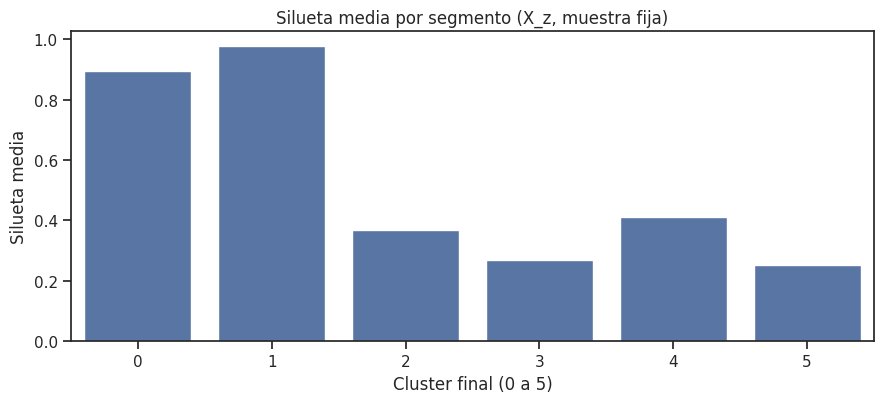

In [ ]:
# @title
# Silueta por proveedor en la muestra común (n = 10 000) sobre X_z
silueta_prov = pd.Series(silhouette_samples(X_z[muestra_z], df["cluster_final"].values[muestra_z]))
silueta_seg = pd.DataFrame({
    "cluster_final": df["cluster_final"].values[muestra_z],
    "segmento": df["segmento"].values[muestra_z],
    "silueta": silueta_prov.values,
})
resumen_sil = silueta_seg.groupby(["cluster_final", "segmento"])["silueta"].agg(
    Silueta_media="mean",
    Silueta_mediana="median",
    Prop_negativa_pct=lambda s: 100 * (s < 0).mean(),
).reset_index()
display(resumen_sil.round(3))

# Diagnóstico de sensibilidad en perfiles únicos (sin duplicados de vector X_z)
mask_unicos = ~df_z.round(6).duplicated()
idx_unicos = np.flatnonzero(mask_unicos.to_numpy())
# Evita calcular todas las distancias cuadráticas de >20 mil perfiles únicos a la vez.
idx_unicos_muestra = np.random.RandomState(SEED + 88).choice(
    idx_unicos, size=min(TAM_MUESTRA_SILUETA, len(idx_unicos)), replace=False
)
sil_unicos = silhouette_score(X_z[idx_unicos_muestra], df["cluster_final"].values[idx_unicos_muestra])
print(f"Silueta en muestra de {len(idx_unicos_muestra)} perfiles únicos (de {mask_unicos.sum()}): {sil_unicos:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=resumen_sil, x="cluster_final", y="Silueta_media", color="#4c72b0", ax=ax)
ax.set(
    title="Silueta media por segmento (X_z, muestra fija)",
    xlabel="Cluster final (0 a 5)",
    ylabel="Silueta media",
)
plt.tight_layout()
plt.show()

**Lectura de validación.** El ARI entre semillas mide coincidencia entre particiones (no porcentaje de aciertos). Comparar el ARI efectivamente impreso y la silueta de los vectores únicos frente a la silueta general: **muchos perfiles repetidos pueden aumentar artificialmente la compacidad aparente**. Un nivel alto de ARI no convierte automáticamente los clusters en categorías económicas inequívocas. Para redactar el paper, copiar los resultados de las tablas exportadas, no números del Hito 3.

### 05.1. Experimento de sensibilidad: ¿`n_items_adjudicados` está duplicando información?

**Hipótesis a evaluar, no conclusión:** las variables `n_items_adjudicados`, `tasa_adjudicacion` y `monto_total_adjudicado` están relacionadas. Una diferencia repetida puede tener peso adicional en la distancia euclidiana. Aquí **reentrenamos** K-means sobre seis atributos excluyendo `n_items_adjudicados` y comparamos con el modelo de siete variables.

**Regla de interpretación:** un ARI alto indica que las particiones son similares, **no** prueba que eliminar un atributo sea lo correcto. La silueta interna de seis y siete dimensiones no es directamente comparable; para una comparación auxiliar calculamos también la silueta de *ambas particiones en el mismo espacio de siete atributos* sobre la misma muestra. Evaluar, sobre todo, si los grupos conservan diferencias comprensibles en éxito, escala, recurrencia y territorio. **El modelo oficial de este cuaderno sigue siendo de siete atributos hasta una decisión documentada.**

In [ ]:
# Contraste realizado sobre los mismos RUC; se calcula cuando se ejecuta el notebook real.
VARIABLES_6 = [v for v in VARIABLES if v != "n_items_adjudicados"]
X_6 = df_z[VARIABLES_6].to_numpy()
modelo_6 = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X_6)
lab_6 = modelo_6.labels_
lab_7 = df["cluster_final"].to_numpy()
muestra_sensibilidad = np.random.RandomState(SEED + 19).choice(
    len(df), size=min(3500, len(df)), replace=False
)
resumen_sensibilidad = pd.DataFrame([
    {"Configuracion": "7 atributos (modelo principal)", "n_atributos": 7,
     "ARI_frente_7": 1.0,
     "Silueta_en_7D_comun": float(silhouette_score(X_z[muestra_sensibilidad], lab_7[muestra_sensibilidad])),
     "Tam_min_pct": float(100 * np.bincount(lab_7).min() / len(df))},
    {"Configuracion": "6 atributos (sin ítems adjudicados)", "n_atributos": 6,
     "ARI_frente_7": float(adjusted_rand_score(lab_7, lab_6)),
     "Silueta_en_7D_comun": float(silhouette_score(X_z[muestra_sensibilidad], lab_6[muestra_sensibilidad])),
     "Tam_min_pct": float(100 * np.bincount(lab_6).min() / len(df))},
])
resumen_sensibilidad.to_csv(RUTA_TABLAS / "sensibilidad_sin_items_adjudicados.csv", index=False)
print("¿Cambia la segmentación al retirar el conteo de ítems adjudicados?")
display(resumen_sensibilidad.round(3))
print("Interpretar junto al perfilado: una sola métrica no decide si el atributo es prescindible.")

¿Cambia la segmentación al retirar el conteo de ítems adjudicados?


,Configuracion,n_atributos,ARI_frente_7,Silueta_en_7D_comun,Tam_min_pct
0,7 atributos (modelo principal),7,1.000,0.794,2.699
1,6 atributos (sin ítems adjudicados),6,0.993,0.793,3.151


Interpretar junto al perfilado: una sola métrica no decide si el atributo es prescindible.


# <font color=green>06. Perfilado e interpretación de clusters en unidades originales</font>
Calculamos la tabla definitiva de perfiles en unidades originales sobre las etiquetas de K-means en 7 variables (`X_z`) y graficamos el mapa de calor de centroides estandarizados y la distribución del tamaño y monto adjudicado.

In [ ]:
# @title
df["tiene_adjudicacion"] = (df["n_items_adjudicados"] > 0).astype(int)

perfil = df.groupby(["cluster_final", "segmento"]).agg(
    n_proveedores=("ruc_proveedor", "size"),
    conv_mediana=("n_convocatorias", "median"),
    conv_media=("n_convocatorias", "mean"),
    items_mediana=("n_items_adjudicados", "median"),
    items_media=("n_items_adjudicados", "mean"),
    pct_con_adjudicacion=("tiene_adjudicacion", lambda s: 100 * s.mean()),
    tasa_media=("tasa_adjudicacion", "mean"),
    monto_mediana=("monto_total_adjudicado", "median"),
    monto_total=("monto_total_adjudicado", "sum"),
    municip_mediana=("n_municipalidades", "median"),
    municip_media=("n_municipalidades", "mean"),
    rubros_media=("n_rubros", "mean"),
    dias_mediana=("dias_trayectoria", "median"),
    pct_consorcio_ext=("participa_en_consorcio", lambda s: 100 * s.mean()),
    pct_penalidades_ext=("tiene_penalidades", lambda s: 100 * s.mean()),
).reset_index()

perfil["porcentaje_proveedores"] = 100 * perfil["n_proveedores"] / len(df)
perfil["pct_monto_total"] = 100 * perfil["monto_total"] / perfil["monto_total"].sum()

perfil.to_csv(RUTA_TABLAS / "perfil_clusters.csv", index=False)
display(perfil.round(2))

# Concentración global del monto adjudicado
montos_ord = df["monto_total_adjudicado"].sort_values(ascending=False)
for pct_top in [1, 5]:
    n_top = int(len(df) * pct_top / 100)
    print(f"El {pct_top}% de los proveedores ({n_top}) concentra el {montos_ord.head(n_top).sum() / montos_ord.sum():.1%} del monto total adjudicado.")
# Control de calidad: indicador de penalidad puede estar mal emparejado con adjudicaciones.
audit_penal = pd.DataFrame([{
    "Proveedores_con_penalidad": int(df["tiene_penalidades"].fillna(0).astype(bool).sum()),
    "Penalidad_y_cero_items": int((df["tiene_penalidades"].fillna(0).astype(bool) & df["n_items_adjudicados"].eq(0)).sum()),
    "Nota": "Validación de llaves pendiente: no interpretar sanciones/riesgo a partir de clusters",
}])
audit_penal.to_csv(RUTA_TABLAS / "auditoria_penalidades.csv", index=False)
print("Auditoría de calidad del indicador de penalidad (no utilizar como conclusión causal):")
display(audit_penal)

,cluster_final,segmento,n_proveedores,conv_mediana,conv_media,items_mediana,items_media,pct_con_adjudicacion,tasa_media,monto_mediana,monto_total,municip_mediana,municip_media,rubros_media,dias_mediana,pct_consorcio_ext,pct_penalidades_ext,porcentaje_proveedores,pct_monto_total
0,0,Seg.1 Ganadores de una sola vez,13847,1.0,1.04,1.0,1.03,100.00,0.99,232833.56,1.709e+10,1.0,1.00,1.00,0.0,7.36,1.03,29.29,67.47
1,1,Seg.2 Postores de una sola vez sin éxito,22712,1.0,1.05,0.0,0.00,0.00,0.00,0.00,0.000e+00,1.0,1.00,1.00,0.0,7.37,1.27,48.04,0.00
2,2,Seg.3 Postores recurrentes sin éxito,3504,3.0,4.01,0.0,0.00,0.00,0.00,0.00,0.000e+00,2.0,2.32,1.00,315.0,28.65,5.91,7.41,0.00
3,3,Seg.4 Ganadores recurrentes,4173,4.0,4.75,2.0,2.28,100.00,0.53,211024.80,3.482e+09,2.0,1.91,1.00,525.0,31.01,6.30,8.83,13.74
4,4,Seg.5 Generalistas multirrubro,1769,5.0,7.25,1.0,1.85,65.91,0.30,125000.00,1.568e+09,2.0,3.33,2.05,731.0,52.74,10.80,3.74,6.19
5,5,Seg.6 Grandes operadores multimunicipales,1276,20.0,32.95,4.0,7.53,92.01,0.24,688837.31,3.191e+09,9.0,12.23,1.03,1259.5,38.64,14.58,2.70,12.60


El 1% de los proveedores (472) concentra el 41.9% del monto total adjudicado.
El 5% de los proveedores (2364) concentra el 72.5% del monto total adjudicado.
Auditoría de calidad del indicador de penalidad (no utilizar como conclusión causal):


,Proveedores_con_penalidad,Penalidad_y_cero_items,Nota
0,1278,569,Validación de llaves pendiente: no interpretar...


In [ ]:
# @title
# Auditoría cualitativa y reproducible de nombres heredados: NO se deducen automáticamente del índice del cluster.
def revisar_nombre(fila):
    seg = int(fila["cluster_final"])
    if seg in [0, 1]:
        return bool(fila["conv_mediana"] <= 1.5)
    if seg == 2:
        return bool(fila["pct_con_adjudicacion"] <= 10)
    if seg == 3:
        return bool(fila["pct_con_adjudicacion"] >= 20)
    if seg == 4:
        return bool(fila["rubros_media"] > 1.5)
    if seg == 5:
        return bool(fila["municip_mediana"] >= 2)
    return False

revision_nombres = perfil[["cluster_final", "segmento", "conv_mediana",
                           "pct_con_adjudicacion", "municip_mediana", "rubros_media"]].copy()
revision_nombres["Heuristica_minima_cumplida"] = revision_nombres.apply(revisar_nombre, axis=1)
revision_nombres.to_csv(RUTA_TABLAS / "revision_nombres_segmentos.csv", index=False)
display(revision_nombres.round(2))
if not revision_nombres["Heuristica_minima_cumplida"].all():
    print("ATENCIÓN: uno o más nombres NO concuerdan con su perfil; renombrar antes del paper y los mapas.")
else:
    print("Chequeo heurístico básico superado: igualmente revisar nombres y medianas antes de presentar.")

,cluster_final,segmento,conv_mediana,pct_con_adjudicacion,municip_mediana,rubros_media,Heuristica_minima_cumplida
0,0,Seg.1 Ganadores de una sola vez,1.0,100.00,1.0,1.00,True
1,1,Seg.2 Postores de una sola vez sin éxito,1.0,0.00,1.0,1.00,True
2,2,Seg.3 Postores recurrentes sin éxito,3.0,0.00,2.0,1.00,True
3,3,Seg.4 Ganadores recurrentes,4.0,100.00,2.0,1.00,True
4,4,Seg.5 Generalistas multirrubro,5.0,65.91,2.0,2.05,True
5,5,Seg.6 Grandes operadores multimunicipales,20.0,92.01,9.0,1.03,True


Chequeo heurístico básico superado: igualmente revisar nombres y medianas antes de presentar.


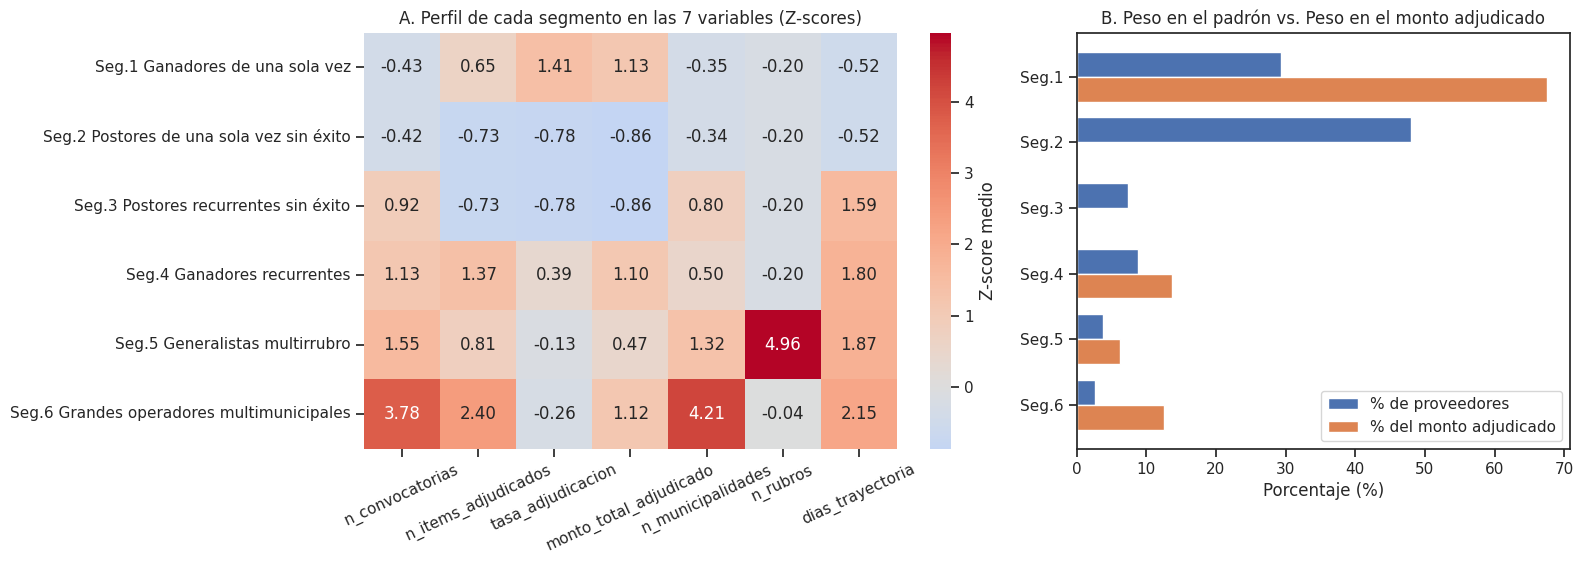

In [ ]:
# @title
centros_z = pd.DataFrame(X_z, columns=VARIABLES).groupby(df["segmento"].values).mean()
centros_z = centros_z.loc[[NOMBRES_SEGMENTOS[i] for i in range(K_FINAL)]]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [1.35, 1]})

sns.heatmap(centros_z, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"label": "Z-score medio"})
axes[0].set(title="A. Perfil de cada segmento en las 7 variables (Z-scores)", xlabel="", ylabel="")
axes[0].tick_params(axis="x", rotation=25)

y_pos = np.arange(K_FINAL)
alto = 0.38
axes[1].barh(y_pos - alto/2, perfil["porcentaje_proveedores"], height=alto, color="#4c72b0", label="% de proveedores")
axes[1].barh(y_pos + alto/2, perfil["pct_monto_total"], height=alto, color="#dd8452", label="% del monto adjudicado")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f"Seg.{i+1}" for i in range(K_FINAL)])
axes[1].invert_yaxis()
axes[1].set(title="B. Peso en el padrón vs. Peso en el monto adjudicado", xlabel="Porcentaje (%)")
axes[1].legend()

plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "perfil_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretación de los segmentos (obligatoria después de ejecutar).** Los seis nombres impresos por el código son **etiquetas tentativas heredadas del Hito 3** y ordenadas a partir de criterios heurísticos (adjudicación, recorrencia, municipalidades y rubros). No constituyen una clasificación externa validada.

1. Verificar en `perfil_clusters.csv` que los segmentos llamados **de una sola vez** tengan `conv_mediana = 1` y trayectoria breve.
2. Verificar que el grupo **sin éxito** muestre tasas de adjudicación cercanas a cero; si aparece adjudicación sustancial, **renombrarlo**.
3. Verificar que **multirrubro** realmente destaque en `rubros_media` y **multimunicipal** en `municip_mediana`/`municip_media`.
4. Evitar afirmar que los postores no ganaron por fallar en admisión, precio, barreras de entrada u otras causas **no observadas en la matriz**.
5. Las penalidades cruzadas por RUC y año contienen incidencias no resueltas; mostrarlas solo como auditoría, no como evidencia de cumplimiento o riesgo.

**Para el paper:** citar el tamaño, la mediana de participación y el porcentaje de adjudicatarios **obtenidos en esta ejecución**, y explicar su utilidad como segmentación descriptiva. No reutilizar las cifras de los seis grupos formados previamente sobre PCA.
**Nota:** para cualquier valor de `k` distinto de 6, la renumeración/nombres y los mapas deben redefinirse; no basta con cambiar `K_FINAL`.


## 07. Vinculación geográfica y cobertura provincial

La información se asocia a **provincias de participación**, no a coordenadas de la sede del proveedor. Se construyen apariciones únicas **RUC–provincia** y se agregan totales y porcentajes por segmento para cada una de las 196 provincias.

**Control de ambigüedad:** en la cartografía usada se verifica si los nombres provinciales son unívocos. Si existiesen homónimos, la unión solo por nombre quedaría **invalidada** y sería obligatorio obtener la clave departamento–provincia o UBIGEO desde la fuente. El identificador compuesto `NOMBDEP + provincia` se utiliza al unir las tablas y geometrías **tras** comprobar que el nombre identifica realmente una provincia. No se deben inventar departamentos para resolver ambigüedades.

**Indicador recurrente:** se define directamente como proveedor con `n_convocatorias > 1`, no como suma automática de determinados números de cluster; así no depende del nombre provisional de los segmentos.

**Interpretación:** una proporción provincial refleja composición de proveedores que **participaron en contrataciones de la municipalidad provincial**, no concentración de empresas domiciliadas allí. El umbral de 100 proveedores se aplica a mapas porcentuales por estabilidad de denominadores, no oculta los conteos absolutos.

In [ ]:
# @title
def cargar_limites():
    ruta = ARCHIVO_LIM_JSON if ARCHIVO_LIM_JSON.exists() else ARCHIVO_GEOJSON_ALT
    if not ruta.exists():
        if str(ARCHIVO_LIM_JSON).startswith("limites-peru-geojson"):
            subprocess.run(["git", "clone", "--depth", "1", REPO_LIMITES, "limites-peru-geojson"], check=True)
            ruta = ARCHIVO_LIM_JSON if ARCHIVO_LIM_JSON.exists() else ARCHIVO_GEOJSON_ALT
    assert ruta.exists(), f"No se encontró el archivo cartográfico: {ruta}"
    limites = gpd.read_file(ruta)
    if limites.crs is None:
        limites = limites.set_crs(epsg=4326)
    else:
        limites = limites.to_crs(epsg=4326)

    limites["NOMBDEP"] = limites["NOMBDEP"].map(normalizar_texto)
    limites["provincia"] = (
        limites["NOMBPROV"]
        .astype(str)
        .str.replace("\x91", "", regex=False)
        .map(normalizar_texto)
        .replace({"NASCA": "NAZCA"})
    )
    assert limites["provincia"].is_unique, "Existen nombres de provincia duplicados en el archivo de límites."
    limites["id_provincia"] = limites["NOMBDEP"] + "_" + limites["provincia"]
    assert limites["id_provincia"].is_unique, "La clave compuesta id_provincia no es única."
    return limites


limites = cargar_limites()
mapa_prov_a_id = dict(zip(limites["provincia"], limites["id_provincia"]))

df["es_recurrente"] = df["n_convocatorias"].gt(1).astype(int)
apariciones_prov = df[["ruc_proveedor", "cluster_final", "segmento", "es_recurrente", "provincias_participacion"]].copy()
apariciones_prov["provincia"] = apariciones_prov["provincias_participacion"].fillna("").str.split(",")
apariciones_prov = apariciones_prov.explode("provincia").reset_index(drop=True)
apariciones_prov["provincia"] = (
    apariciones_prov["provincia"]
    .astype(str)
    .map(normalizar_texto)
    .replace({"NASCA": "NAZCA"})
)
apariciones_prov = apariciones_prov[apariciones_prov["provincia"] != ""].copy()
apariciones_prov["id_provincia"] = apariciones_prov["provincia"].map(mapa_prov_a_id)

# Validaciones estrictas pedidas en la guía
sin_correspondencia = apariciones_prov["id_provincia"].isna().sum()
assert sin_correspondencia == 0, f"Existen {sin_correspondencia} registros sin correspondencia geográfica."

apariciones_prov = apariciones_prov.drop_duplicates(["ruc_proveedor", "id_provincia"]).reset_index(drop=True)
assert apariciones_prov[["ruc_proveedor", "id_provincia"]].duplicated().sum() == 0

auditoria_join = pd.DataFrame([{
    "provincias_en_limites": len(limites),
    "provincias_con_proveedores": apariciones_prov["id_provincia"].nunique(),
    "apariciones_ruc_provincia": len(apariciones_prov),
    "promedio_provincias_por_ruc": round(len(apariciones_prov) / len(df), 3),
    "registros_sin_match": int(sin_correspondencia),
    "tasa_cobertura_pct": 100.0,
}])
auditoria_join.to_csv(RUTA_TABLAS / "auditoria_union_geografica.csv", index=False)
display(auditoria_join)
# Cierre del ejemplo exigido en el pipeline: muestra dónde participó un proveedor, sin exponer su RUC.
prov_ej = apariciones_prov.loc[
    apariciones_prov["ruc_proveedor"].eq(df.loc[idx_ejemplo, "ruc_proveedor"]),
    ["provincia", "id_provincia", "segmento"]
]
print("Ejemplo del pipeline: proveedor anonimizado -> segmento y provincias de participación")
display(prov_ej.assign(proveedor="RUC_EJEMPLO").head(10))

,provincias_en_limites,provincias_con_proveedores,apariciones_ruc_provincia,promedio_provincias_por_ruc,registros_sin_match,tasa_cobertura_pct
0,196,196,74244,1.57,0,100.0


Ejemplo del pipeline: proveedor anonimizado -> segmento y provincias de participación


,provincia,id_provincia,segmento,proveedor
2,BELLAVISTA,SAN MARTIN_BELLAVISTA,Seg.4 Ganadores recurrentes,RUC_EJEMPLO
3,DATEM DEL MARANON,LORETO_DATEM DEL MARANON,Seg.4 Ganadores recurrentes,RUC_EJEMPLO


In [ ]:
# @title
tabla_prov_conteos = pd.crosstab(apariciones_prov["id_provincia"], apariciones_prov["segmento"])
cols_seg = [NOMBRES_SEGMENTOS[i] for i in range(K_FINAL)]
for col in cols_seg:
    if col not in tabla_prov_conteos.columns:
        tabla_prov_conteos[col] = 0
tabla_prov_conteos = tabla_prov_conteos[cols_seg]

tabla_prov = limites[["id_provincia", "NOMBDEP", "provincia", "NOMBPROV"]].set_index("id_provincia").join(
    tabla_prov_conteos, how="left"
).fillna(0)

for col in cols_seg:
    tabla_prov[col] = tabla_prov[col].astype(int)

tabla_prov["total"] = tabla_prov[cols_seg].sum(axis=1)
assert tabla_prov["total"].ge(0).all()

# Porcentajes sobre el total de proveedores de cada provincia
porcentajes_prov = tabla_prov[cols_seg].div(tabla_prov["total"], axis=0) * 100
assert np.allclose(porcentajes_prov.loc[tabla_prov["total"].gt(0)].sum(axis=1), 100.0, atol=1e-4), "Error en porcentajes de provincias con proveedores"

for i, col in enumerate(cols_seg):
    tabla_prov[f"pct_Seg{i+1}"] = porcentajes_prov[col]
    tabla_prov[f"pct_mapa_Seg{i+1}"] = np.where(tabla_prov["total"] >= MIN_PROVEEDORES, porcentajes_prov[col], np.nan)

# Recurrente = participó en más de una convocatoria (independiente de los nombres de clusters).
recurrentes_por_prov = apariciones_prov.groupby("id_provincia")["es_recurrente"].sum()
tabla_prov["n_recurrentes"] = recurrentes_por_prov.reindex(tabla_prov.index, fill_value=0).astype(int)
tabla_prov["pct_recurrentes"] = 100.0 * tabla_prov["n_recurrentes"] / tabla_prov["total"].replace(0, np.nan)
tabla_prov["pct_mapa_recurrentes"] = np.where(
    tabla_prov["total"] >= MIN_PROVEEDORES, tabla_prov["pct_recurrentes"], np.nan
)
tabla_prov["supera_umbral_100"] = tabla_prov["total"] >= MIN_PROVEEDORES

tabla_prov.reset_index().to_csv(RUTA_TABLAS / "estadisticas_provinciales.csv", index=False)

print(f"Provincias que superan el umbral (>= {MIN_PROVEEDORES} proveedores): {int(tabla_prov['supera_umbral_100'].sum())} de {len(tabla_prov)}")
print("\nTop 5 provincias con mayor volumen de proveedores participantes:")
display(tabla_prov.sort_values("total", ascending=False)[["NOMBDEP", "provincia", "total", "pct_Seg1", "pct_Seg2", "pct_Seg6", "pct_recurrentes"]].head(5).round(1))

# Caso Lima Metropolitana frente a las demás provincias comparables (>= 100 proveedores)
comp_umbral = tabla_prov[tabla_prov["supera_umbral_100"]]
fila_lima = comp_umbral.loc["LIMA_LIMA"]
cols_comp = [f"pct_Seg{i+1}" for i in range(K_FINAL)] + ["pct_recurrentes"]
tabla_lima = pd.DataFrame({
    "Lima_Metropolitana_pct": fila_lima[cols_comp].astype(float),
    f"Mediana_{len(comp_umbral)}_provincias_pct": comp_umbral[cols_comp].median().astype(float),
    f"Puesto_Lima_de_{len(comp_umbral)}": [int((comp_umbral[c] > fila_lima[c]).sum() + 1) for c in cols_comp],
})
print(f"\nLima Metropolitana frente a las {len(comp_umbral)} provincias con al menos {MIN_PROVEEDORES} proveedores:")
display(tabla_lima.round(1))

Provincias que superan el umbral (>= 100 proveedores): 177 de 196

Top 5 provincias con mayor volumen de proveedores participantes:


,NOMBDEP,provincia,total,pct_Seg1,pct_Seg2,pct_Seg6,pct_recurrentes
id_provincia,,,,,,,
LIMA_LIMA,LIMA,LIMA,2319,9.7,49.1,9.9,42.9
CUSCO_ESPINAR,CUSCO,ESPINAR,1808,6.5,28.4,21.1,68.0
ANCASH_SANTA,ANCASH,SANTA,1347,30.9,36.5,13.9,34.4
CUSCO_CANCHIS,CUSCO,CANCHIS,1297,4.9,36.7,25.1,60.7
CAJAMARCA_CAJAMARCA,CAJAMARCA,CAJAMARCA,1240,10.7,53.0,14.4,38.5



Lima Metropolitana frente a las 177 provincias con al menos 100 proveedores:


,Lima_Metropolitana_pct,Mediana_177_provincias_pct,Puesto_Lima_de_177
pct_Seg1,9.7,21.7,153
pct_Seg2,49.1,27.2,4
pct_Seg3,13.7,9.9,20
pct_Seg4,10.4,10.4,88
pct_Seg5,7.2,6.9,83
pct_Seg6,9.9,20.8,170
pct_recurrentes,42.9,50.7,128


# <font color=green>08. Mapa interactivo de clusters (HTML) y figura para el paper</font>
Generamos el mapa interactivo con `Plotly` incluyendo la vista de volumen absoluto, las vistas porcentuales de **los 6 segmentos finales** y el agregado de recurrentes, con llave única `id_provincia`, `hover` completo (conteo absoluto, denominador provincial y porcentaje) y exportación offline en `outputs/mapas/mapa_clusters_proveedores.html`.

In [ ]:
# @title
import json
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from shapely.geometry import MultiPolygon
from shapely.geometry.polygon import orient
from matplotlib.colors import to_hex
import matplotlib.pyplot as plt

mapa_geo = limites.merge(tabla_prov.reset_index().drop(columns=["NOMBDEP", "provincia", "NOMBPROV"]), on="id_provincia", how="left", validate="1:1")
mapa_geo["geometry"] = mapa_geo.geometry.simplify(0.02, preserve_topology=True).set_precision(0.001)

# Aplicamos orientación de polígonos requerida para evitar inversión de relleno en Plotly
for capa in (mapa_geo,):
    capa["geometry"] = capa.geometry.apply(
        lambda g: MultiPolygon([orient(p, sign=-1.0) for p in (g.geoms if g.geom_type == "MultiPolygon" else [g])])
    )

cortes = [0, 100, 200, 400, 800, 1200, 2000, np.inf]
etiquetas_rango = ["Menos de 100", "100 a 199", "200 a 399", "400 a 799", "800 a 1199", "1200 a 1999", "2000 o más"]
mapa_geo["rango_proveedores"] = pd.cut(mapa_geo["total"], bins=cortes, labels=etiquetas_rango, right=False)
mapa_geo["indice_rango"] = mapa_geo["rango_proveedores"].cat.codes

geojson_prov = json.loads(mapa_geo.set_index("id_provincia")[["geometry"]].to_json())
deptos = mapa_geo[["NOMBDEP", "geometry"]].dissolve(by="NOMBDEP").reset_index()

for capa in (deptos,):
    capa["geometry"] = capa.geometry.apply(
        lambda g: MultiPolygon([orient(p, sign=-1.0) for p in (g.geoms if g.geom_type == "MultiPolygon" else [g])])
    )
geojson_deptos = json.loads(deptos.set_index("NOMBDEP")[["geometry"]].to_json())

n = len(etiquetas_rango)
hex_rango = [to_hex(c) for c in plt.cm.YlGnBu(np.linspace(0.12, 1.0, n))]
escala_rango = [[p, hex_rango[i]] for i in range(n) for p in (i / n, (i + 1) / n)]
escala_continua = [[i / 10, to_hex(plt.cm.YlGnBu(0.12 + 0.88 * i / 10))] for i in range(11)]

opciones = [
    ("indice_rango", "Proveedores por provincia"),
    ("pct_mapa_recurrentes", "% recurrentes (n_convocatorias > 1)"),
    ("pct_mapa_Seg1", "% Seg.1 Ganadores de una sola vez"),
    ("pct_mapa_Seg2", "% Seg.2 Postores de una sola vez sin éxito"),
    ("pct_mapa_Seg3", "% Seg.3 Postores recurrentes sin éxito"),
    ("pct_mapa_Seg4", "% Seg.4 Ganadores recurrentes"),
    ("pct_mapa_Seg5", "% Seg.5 Generalistas multirrubro"),
    ("pct_mapa_Seg6", "% Seg.6 Grandes operadores multimunicipales")
]

fig = go.Figure()
fig.add_trace(go.Choropleth(
    geojson=geojson_prov,
    locations=mapa_geo["id_provincia"],
    z=[0] * len(mapa_geo),
    colorscale=[[0, "lightgrey"], [1, "lightgrey"]],
    showscale=False,
    marker_line_width=0.3,
    marker_line_color="white",
    hoverinfo="skip"
))

for k, (columna, boton) in enumerate(opciones):
    if columna == "indice_rango":
        extra = dict(
            colorscale=escala_rango,
            zmin=-0.5,
            zmax=n - 0.5,
            colorbar=dict(title="Proveedores", tickvals=list(range(n)), ticktext=etiquetas_rango, len=0.7, thickness=15)
        )
        hover = "<b>%{text}</b> (%{customdata[0]})<br>Proveedores: %{customdata[1]} (%{customdata[2]})<extra></extra>"
    else:
        extra = dict(
            colorscale=escala_continua,
            zmin=np.floor(mapa_geo[columna].min()) if not mapa_geo[columna].isna().all() else 0,
            zmax=np.ceil(mapa_geo[columna].max()) if not mapa_geo[columna].isna().all() else 100,
            colorbar=dict(title="% de proveedores<br>de la provincia", ticksuffix=" %", len=0.7, thickness=15)
        )
        hover = "<b>%{text}</b> (%{customdata[0]})<br>Proveedores: %{customdata[1]}<br>" + boton + ": %{z:.1f} %<extra></extra>"

    fig.add_trace(go.Choropleth(
        geojson=geojson_prov,
        locations=mapa_geo["id_provincia"],
        z=mapa_geo[columna],
        text=mapa_geo["NOMBPROV"],
        customdata=np.column_stack([
            mapa_geo["NOMBDEP"],
            mapa_geo["total"].fillna(0).astype(int),
            mapa_geo["rango_proveedores"].astype(str)
        ]),
        hovertemplate=hover,
        marker_line_width=0.3,
        marker_line_color="white",
        visible=(k == 0),
        **extra
    ))

fig.add_trace(go.Choropleth(
    geojson=geojson_deptos,
    locations=deptos["NOMBDEP"],
    z=[0] * len(deptos),
    colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]],
    showscale=False,
    marker_line_width=1.2,
    marker_line_color="#333333",
    hoverinfo="skip"
))

botones = [
    dict(
        label=boton,
        method="update",
        args=[
            {"visible": [True] + [j == k for j in range(len(opciones))] + [True]},
            {"title": {"text": boton + " (gris: menos de 100 proveedores)" if k > 0 else boton}}
        ]
    )
    for k, (columna, boton) in enumerate(opciones)
]

fig.update_geos(
    visible=False,
    lonaxis_range=[-82, -68],
    lataxis_range=[-19, 0.5],
    showland=True,
    landcolor="#f4f4f4",
    showocean=True,
    oceancolor="#e6f0f7",
    showcountries=True,
    countrycolor="#bbbbbb"
)

fig.update_layout(
    height=760,
    margin=dict(l=0, r=0, t=70, b=0),
    title={"text": opciones[0][1]},
    template="plotly_white",
    updatemenus=[dict(buttons=botones, direction="down", x=0.01, y=1.0, xanchor="left", yanchor="top")]
)

ruta_html = RUTA_MAPAS / "mapa_clusters_proveedores.html"
fig.write_html(str(ruta_html), include_plotlyjs="cdn")
print(f"Mapa HTML guardado en: {ruta_html}")
fig.show()

Mapa HTML guardado en: outputs/mapas/mapa_clusters_proveedores.html


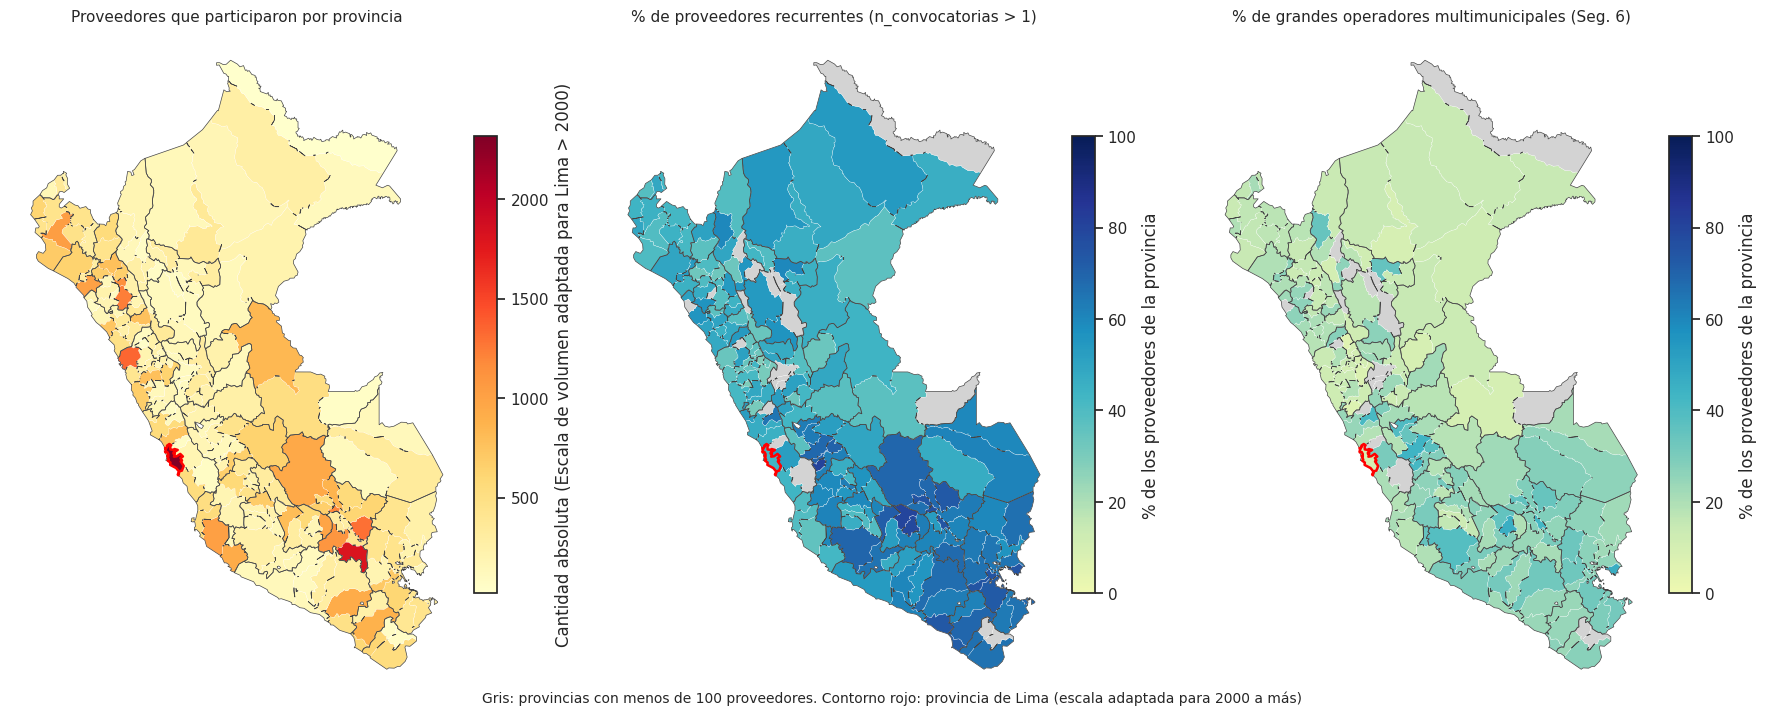

Mapa estático guardado en: outputs/figuras/mapa_provincias_paper.png


In [ ]:
# @title
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
import numpy as np
import matplotlib.pyplot as plt

deptos_mapa = mapa_geo[["NOMBDEP", "geometry"]].dissolve(by="NOMBDEP")
lima = mapa_geo[mapa_geo["provincia"] == "LIMA"]

mapas = [
    ("total", "Proveedores que participaron por provincia"),
    ("pct_mapa_recurrentes", "% de proveedores recurrentes (n_convocatorias > 1)"),
    ("pct_mapa_Seg6", "% de grandes operadores multimunicipales (Seg. 6)")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 9))
colores_continuo = ListedColormap(plt.cm.YlGnBu(np.linspace(0.12, 1.0, 256)))

for ax, (columna, titulo) in zip(axes, mapas):
    if columna == "total":
        valores = mapa_geo[columna].fillna(0)
        # Se ajusta la escala para dar visibilidad al volumen de Lima que supera los 2000 proveedores
        norma = plt.Normalize(vmin=valores.min(), vmax=valores.max())
        mapa_geo.plot(column=columna, cmap="YlOrRd", norm=norma, ax=ax, edgecolor="white", linewidth=0.2,
                      missing_kwds={"color": "lightgrey"})
    else:
        valores = mapa_geo[columna].dropna()
        norma = plt.Normalize(vmin=0, vmax=100)
        mapa_geo.plot(column=columna, cmap=colores_continuo, norm=norma, ax=ax, edgecolor="white", linewidth=0.2,
                      missing_kwds={"color": "lightgrey"})

    deptos_mapa.boundary.plot(ax=ax, color="#444444", linewidth=0.5)
    if not lima.empty:
        lima.boundary.plot(ax=ax, color="red", linewidth=1.8)

    barra = fig.colorbar(ScalarMappable(norm=norma, cmap="YlOrRd" if columna == "total" else colores_continuo),
                         ax=ax, shrink=0.55, pad=0.02)
    if columna == "total":
        barra.set_label("Cantidad absoluta (Escala de volumen adaptada para Lima > 2000)")
    else:
        barra.set_label("% de los proveedores de la provincia")

    ax.set_title(titulo, fontsize=11)
    ax.axis("off")

fig.suptitle("Gris: provincias con menos de 100 proveedores. Contorno rojo: provincia de Lima (escala adaptada para 2000 a más)", y=0.12, fontsize=10)
plt.tight_layout()

ruta_mapas_paper = RUTA_FIGURAS / "mapa_provincias_paper.png"
plt.savefig(str(ruta_mapas_paper), dpi=200, bbox_inches="tight")
plt.show()
print(f"Mapa estático guardado en: {ruta_mapas_paper}")

## 09. Discusión, conclusiones y recomendaciones (evidencia, interpretación y límites)

Las secciones **V, VI y VII del paper** no deben repetir cifras de otros hitos: deben basarse exclusivamente en las tablas generadas al ejecutar este cuaderno. El orden recomendado es **resultado cuantitativo → interpretación del patrón → posible utilidad para el usuario → límite de inferencia**.

**Resultados (V).** Presentar `comparacion_kmeans_k.csv` y `seleccion_k.png` para justificar `k`, `perfil_clusters.csv` y `perfil_clusters.png` para describir perfiles, y el HTML junto a `mapa_provincias_paper.png` para comparar composición territorial. Explicar la diferencia entre **RUC únicos** y **apariciones proveedor-provincia**. La silueta solo evalúa estructura geométrica, no desempeño institucional.

**Discusión (VI).** Responder qué dimensiones distinguen los segmentos y cómo se distribuyen: recurrencia, adjudicación, escala monetaria y alcance provincial. La **recurrencia** es `n_convocatorias > 1`, no una identidad automática de cuatro clusters. Separar cantidades absolutas de porcentajes y revelar el umbral de 100 proveedores. Describir a Lima como un caso a contrastar, no como una explicación causal.

**Usuarios y utilidad.** El OECE podría utilizar la tipología como **insumo descriptivo de gestión de información** y para formular preguntas de estudio sobre mercados de proveedores. Las municipalidades pueden explorar la composición de quienes concurren a sus procesos. Las empresas pueden consultar patrones históricos agregados, pero **no** se estima probabilidad de obtener contratos ni se recomienda elegir postores con base en los clusters.

**Limitaciones:** 1) proveedores agregados por RUC (no por cada contrato); 2) provincia de participación (no domicilio fiscal); 3) atributos correlacionados y sensibilidad a la selección; 4) perfiles idénticos que inflan métricas; 5) penalidades con integración por validar; 6) agregación de cinco años, sin causalidad o evolución temporal; 7) K-means supone agrupaciones que pueden describir mal fronteras graduales; 8) porcentajes restringidos a provincias de muestra suficiente.

**Conclusiones (VII):** responder la pregunta con el número y características de grupos recalculados y con contrastes territoriales concretos. Indicar siempre que se trata de **tipología descriptiva exploratoria**, no de validación de ilegalidad, barreras de acceso o éxito futuro.

**Recomendaciones:** tablero descriptivo reproducible; profundizar en provincias con composición atípica validando denominadores; estudiar la concurrencia con microdatos de convocatorias; mejorar llaves geográficas y de penalidades; evaluar periodos separados como trabajo futuro. **No** recomendar sanciones, cambios normativos ni selección automática de proveedores basada únicamente en la segmentación.

**Fuentes normativas institucionales (para citar en IEEE, diferentes de fuentes de datos):**
- [Ley N.º 32069, Ley General de Contrataciones Públicas, art. 11](https://cdn.www.gob.pe/uploads/document/file/7594705/6444155-ley-general-de-contrataciones-publicas-con-modificaciones-al-5-12-2025.pdf).
- [ROF del OECE, arts. 4–5](https://cdn.www.gob.pe/uploads/document/file/7966127/6699379-anexo-resolucion-n-002-2025-oece-pre.pdf).


In [ ]:
# Generación automática de evidencia para la discusión; evita copiar conclusiones numéricas del Hito 3.
perfil_breve = perfil[["segmento", "n_proveedores", "porcentaje_proveedores", "conv_mediana",
                       "pct_con_adjudicacion", "tasa_media", "monto_total",
                       "municip_mediana", "rubros_media"]].copy()
perfil_breve.to_csv(RUTA_TABLAS / "resumen_interpretacion_segmentos.csv", index=False)
print("TABLA BASE PARA INTERPRETAR EL HITO 4 (resultados de esta ejecución):")
display(perfil_breve.round(2))

impacto_oece = pd.DataFrame([
    {"Funcion_OECE": "Gestión de información", "Evidencia_notebook": "perfil_clusters.csv + mapa HTML",
     "Uso_posible": "Comparar composición y diversidad de proveedores", "Advertencia": "Diagnóstico descriptivo, no causal"},
    {"Funcion_OECE": "Supervisión selectiva", "Evidencia_notebook": "estadisticas_provinciales.csv",
     "Uso_posible": "Orientar preguntas para análisis posteriores", "Advertencia": "No identifica infracciones ni clasifica riesgo legal"},
    {"Funcion_OECE": "Asistencia técnica", "Evidencia_notebook": "tablas de perfiles y comparativas provinciales",
     "Uso_posible": "Detectar dónde investigar necesidades de orientación", "Advertencia": "Requiere evidencia adicional de procesos y causas"},
    {"Funcion_OECE": "Herramientas digitales", "Evidencia_notebook": "mapa_clusters_proveedores.html",
     "Uso_posible": "Prototipo exploratorio de composición provincial", "Advertencia": "No está integrado a sistemas oficiales"},
])
impacto_oece.to_csv(RUTA_TABLAS / "usos_posibles_oece.csv", index=False)
display(impacto_oece)
print("Nota: los segmentos solo describen los datos de proveedores 2021-2025; sus usos requieren validación posterior.")

TABLA BASE PARA INTERPRETAR EL HITO 4 (resultados de esta ejecución):


,segmento,n_proveedores,porcentaje_proveedores,conv_mediana,pct_con_adjudicacion,tasa_media,monto_total,municip_mediana,rubros_media
0,Seg.1 Ganadores de una sola vez,13847,29.29,1.0,100.00,0.99,1.709e+10,1.0,1.00
1,Seg.2 Postores de una sola vez sin éxito,22712,48.04,1.0,0.00,0.00,0.000e+00,1.0,1.00
2,Seg.3 Postores recurrentes sin éxito,3504,7.41,3.0,0.00,0.00,0.000e+00,2.0,1.00
3,Seg.4 Ganadores recurrentes,4173,8.83,4.0,100.00,0.53,3.482e+09,2.0,1.00
4,Seg.5 Generalistas multirrubro,1769,3.74,5.0,65.91,0.30,1.568e+09,2.0,2.05
5,Seg.6 Grandes operadores multimunicipales,1276,2.70,20.0,92.01,0.24,3.191e+09,9.0,1.03


,Funcion_OECE,Evidencia_notebook,Uso_posible,Advertencia
0,Gestión de información,perfil_clusters.csv + mapa HTML,Comparar composición y diversidad de proveedores,"Diagnóstico descriptivo, no causal"
1,Supervisión selectiva,estadisticas_provinciales.csv,Orientar preguntas para análisis posteriores,No identifica infracciones ni clasifica riesgo...
2,Asistencia técnica,tablas de perfiles y comparativas provinciales,Detectar dónde investigar necesidades de orien...,Requiere evidencia adicional de procesos y causas
3,Herramientas digitales,mapa_clusters_proveedores.html,Prototipo exploratorio de composición provincial,No está integrado a sistemas oficiales


Nota: los segmentos solo describen los datos de proveedores 2021-2025; sus usos requieren validación posterior.


In [ ]:
# Síntesis cuantitativa reproducible para orientar la discusión y las conclusiones.
# NO sustituye la revisión crítica: los nombres y relaciones geográficas deben validarse.
seg_mayor = perfil.sort_values("n_proveedores", ascending=False).iloc[0]
comparables = tabla_prov.loc[tabla_prov["total"].ge(MIN_PROVEEDORES)].copy()
comparables = comparables.dropna(subset=["pct_recurrentes"])
if comparables.empty:
    raise ValueError("No hay provincias con denominador suficiente; revisar MIN_PROVEEDORES o fuente.")
prov_min = comparables.sort_values("pct_recurrentes").iloc[0]
prov_max = comparables.sort_values("pct_recurrentes", ascending=False).iloc[0]

resumen_conclusiones = pd.DataFrame([
    {"Eje": "Tipología", "Resultado": f"{K_FINAL} grupos; el mayor es {seg_mayor['segmento']} ({seg_mayor['porcentaje_proveedores']:.1f}% de RUC)",
     "Interpretacion_condicionada": "El grupo predominante requiere interpretar sus atributos originales; no equivale a una categoría legal."},
    {"Eje": "Territorio", "Resultado": f"{len(comparables)} provincias con al menos {MIN_PROVEEDORES} proveedores; recurrencia entre {prov_min['pct_recurrentes']:.1f}% y {prov_max['pct_recurrentes']:.1f}%",
     "Interpretacion_condicionada": "La heterogeneidad es descriptiva; los porcentajes se refieren a proveedores que participaron, no a domicilios."},
    {"Eje": "Método", "Resultado": f"K-means k={K_FINAL}; silueta {criterio_k_final['Silueta']:.3f}; Davies-Bouldin {criterio_k_final['Davies_Bouldin']:.3f}",
     "Interpretacion_condicionada": "La calidad geométrica no prueba validez institucional, legal o predictiva."},
    {"Eje": "Aporte potencial", "Resultado": "Perfiles interpretables y mapa de composición provincial para exploración",
     "Interpretacion_condicionada": "OECE, municipalidades y proveedores deben complementar este análisis con datos y validación externos."},
])
resumen_conclusiones.to_csv(RUTA_TABLAS / "sintesis_para_paper_hito4.csv", index=False)
print("Síntesis para discutir (datos de ESTA ejecución):")
display(resumen_conclusiones)


Síntesis para discutir (datos de ESTA ejecución):


,Eje,Resultado,Interpretacion_condicionada
0,Tipología,6 grupos; el mayor es Seg.2 Postores de una so...,El grupo predominante requiere interpretar sus...
1,Territorio,177 provincias con al menos 100 proveedores; r...,La heterogeneidad es descriptiva; los porcenta...
2,Método,K-means k=6; silueta 0.813; Davies-Bouldin 0.761,La calidad geométrica no prueba validez instit...
3,Aporte potencial,Perfiles interpretables y mapa de composición ...,"OECE, municipalidades y proveedores deben comp..."


# <font color=green>10. Exportación, verificación y aseguramiento de calidad (QA)</font>
Exportamos las tablas finales, figuras para el paper IEEE y mapa interactivo HTML, y ejecutamos las validaciones automáticas del checklist de cierre del Hito 4.

In [ ]:
# Exportación del padrón completo etiquetado
cols_etiquetas = ["ruc_proveedor", "cluster_original", "cluster_final", "segmento"] + VARIABLES
df[cols_etiquetas].to_csv(RUTA_TABLAS / "etiquetas_proveedores.csv", index=False)

# Controles QA obligatorios
assert len(df["cluster_final"]) == len(df), "Longitud de etiquetas no coincide con len(df)."
assert df["cluster_final"].isna().sum() == 0, "Existen proveedores sin cluster asignado."
assert int(perfil["n_proveedores"].sum()) == len(df), "La suma de proveedores por cluster no coincide con len(df)."
assert np.isclose(perfil["porcentaje_proveedores"].sum(), 100.0, atol=1e-4), "Los porcentajes de clusters no suman 100%."
assert np.isclose(perfil["pct_monto_total"].sum(), 100.0, atol=1e-4), "Los porcentajes de monto no suman 100%."

archivos_esperados = [
    RUTA_TABLAS / "validacion_entrada.csv",
    RUTA_TABLAS / "comparacion_kmeans_k.csv",
    RUTA_TABLAS / "correlaciones_7_atributos_completa.csv",
    RUTA_TABLAS / "criterios_decision_k.csv",
    RUTA_TABLAS / "sensibilidad_sin_items_adjudicados.csv",
    RUTA_TABLAS / "resumen_interpretacion_segmentos.csv",
    RUTA_TABLAS / "usos_posibles_oece.csv",
    RUTA_TABLAS / "perfil_clusters.csv",
    RUTA_TABLAS / "revision_nombres_segmentos.csv",
    RUTA_TABLAS / "estadisticas_provinciales.csv",
    RUTA_TABLAS / "auditoria_union_geografica.csv",
    RUTA_TABLAS / "etiquetas_proveedores.csv",
    RUTA_TABLAS / "auditoria_penalidades.csv",
    RUTA_TABLAS / "sintesis_para_paper_hito4.csv",
    RUTA_FIGURAS / "pipeline.png",
    RUTA_FIGURAS / "diagnostico_correlaciones_6_mostradas.png",
    RUTA_FIGURAS / "seleccion_k.png",
    RUTA_FIGURAS / "perfil_clusters.png",
    RUTA_FIGURAS / "mapa_provincias_paper.png",
    RUTA_MAPAS / "mapa_clusters_proveedores.html",
]

reporte_qa = []
for arch in archivos_esperados:
    assert arch.exists() and arch.stat().st_size > 0, f"Archivo faltante o vacío: {arch}"
    reporte_qa.append({
        "Archivo": str(arch),
        "Tamano_KB": round(arch.stat().st_size / 1024, 2),
        "Estado_QA": "VERIFICADO",
    })

print("QA COMPLETADO CON ÉXITO: Todas las tablas, figuras y el mapa HTML fueron generados y validados.")
display(pd.DataFrame(reporte_qa))


QA COMPLETADO CON ÉXITO: Todas las tablas, figuras y el mapa HTML fueron generados y validados.


,Archivo,Tamano_KB,Estado_QA
0,outputs/tablas/validacion_entrada.csv,0.14,VERIFICADO
1,outputs/tablas/comparacion_kmeans_k.csv,1.31,VERIFICADO
2,outputs/tablas/correlaciones_7_atributos_compl...,1.07,VERIFICADO
3,outputs/tablas/criterios_decision_k.csv,0.82,VERIFICADO
4,outputs/tablas/sensibilidad_sin_items_adjudica...,0.24,VERIFICADO
5,outputs/tablas/resumen_interpretacion_segmento...,0.78,VERIFICADO
6,outputs/tablas/usos_posibles_oece.csv,0.65,VERIFICADO
7,outputs/tablas/perfil_clusters.csv,1.62,VERIFICADO
8,outputs/tablas/revision_nombres_segmentos.csv,0.51,VERIFICADO
9,outputs/tablas/estadisticas_provinciales.csv,60.09,VERIFICADO
